# Task 1: Smart Buildings Dataset and Chapter 2 Probability

**Dataset:** `combined_runs.csv` - 60 simulated control runs of the NeurIPS 2026 Smart Buildings challenge (6 buildings x 5 cities x 2 baseline policies, 4,032 five-minute steps each).

# 0. Intro
## Problem
How likely is a 5-minute step of a simulated building-control run to be **heavily penalised** (reward below -0.1), and which conditions - occupancy, weather, controller policy, building - change that probability?

## Why it matters
This is the question behind the NeurIPS 2026 Smart Buildings control challenge. The answer tells us (1) which scenarios are hardest, (2) how to build fair train/validation/test splits (by building and run, not by row, because steps are autocorrelated) and (3) which baseline penalty rate a learned controller must beat.

## Data in one paragraph
One file, `combined_runs.csv`: 241,920 rows x 37 columns. One row = one 5-minute step of one simulation run. There are 60 runs = 6 buildings x 5 weather cities x 2 controller policies (`pid_water` and the noisy `noisy_pid_water`), each with 4,032 steps (14 days). The experiment for all probabilities is: *pick one step at random from the 241,920 equally likely steps*.

## Objectives
1. Understand and prepare the dataset (Sections 1-4).
2. Apply every Chapter 2 concept to real questions: sample space and events, counting, axioms, complement, addition rule, conditional probability, multiplication rule, total probability, Bayes' theorem, independence (Section 5).
3. Validate the main results with independent calculations: rule vs direct count vs an independent re-implementation, block bootstrap, preprocessing and threshold sensitivity (Section 6).
4. Turn the numbers into insights, state the limitations and the use in the competition (Section 7).

## Analysis steps
Load and check the data -> clean and derive columns (with a before/after row log) -> define events (OCC, HP, NOISY, COLD, ...) -> apply the probability rules, one application at a time (question, events and assumptions, rule, calculation, interpretation) -> validate three ways -> summarise findings.

## How to read this notebook
Every code cell is preceded by a text cell saying what is being done and why. Random numbers use seed 42. Run **Runtime > Restart and run all**; no step needs a manual edit. Rule-based and direct-count results are asserted to match exactly.

# 1. Setup
**Purpose.** Load the raw dataset once, keep it untouched in `df_raw`, and confirm its size. All later sections work on copies, so the analysis can be rerun from this cell.

**Link to the textbook (Sec. 2-1.1, 2-1.2).** The random experiment used throughout this notebook is: *select one 5-minute time step at random from the 60 simulated runs*. The sample space S is the set of all 241,920 time steps.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import os

SEED = 42                                  # fixed random seed used everywhere in the notebook
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- Where the data comes from -------------------------------------------------
# The loader tries these sources in order and uses the first one that works:
#   1. a copy of the file in the current Colab folder (drag it into the Files panel)
#   2. the GitHub repo (compressed .gz, pandas reads it directly)
#   3. the shared Google Drive folder (only works if Drive is mounted)
#   4. an upload dialog as the last resort
REPO   = "https://raw.githubusercontent.com/Jana-Hazem/smart-buildings-statistics-project/main"
RAW  = REPO + "/data/raw/combined_runs.csv"
NAME = "combined_runs.csv"                 # the dataset file name
SOURCES = [NAME, NAME + ".gz", "/content/" + NAME,
           RAW,                                      # GitHub copy of the same file
           REPO + "/data/raw/" + NAME + ".gz",
           "/content/drive/MyDrive/stats_project/" + NAME]

def load_raw():
    for s in SOURCES:
        if s.startswith("http") or os.path.exists(s):
            try:
                d = pd.read_csv(s)
                print("Loaded from:", s)
                return d
            except Exception as e:
                print("Could not read", s, "->", type(e).__name__)
    from google.colab import files           # last resort: manual upload
    up = files.upload()
    return pd.read_csv(next(iter(up)))

In [3]:
# Load the raw data. df_raw is never modified after this line.
df_raw = load_raw()
print(df_raw.shape)          # expected: (241920, 37)

Loaded from: https://raw.githubusercontent.com/Jana-Hazem/smart-buildings-statistics-project/main/data/raw/combined_runs.csv
(241920, 37)


In [4]:
# Sanity check against the expected size
assert df_raw.shape == (241920, 37), f"Unexpected shape: {df_raw.shape}"
print("Shape confirmed: 241,920 rows x 37 columns")

Shape confirmed: 241,920 rows x 37 columns


# 2. Dataset understanding

## 2.1 File overview

**Files:** 1 file (`combined_runs.csv`), 241,920 rows × 37 columns.

**What a row means:** one 5-minute time step of one simulated run.

**What a run is:** one simulation of a building under one weather file and one control policy. A run lasts 4,032 steps (14 days × 288 steps per day).

**Run design (counting rule, Sec. 2-1.4):** 6 buildings × 5 cities × 2 policies = 60 runs. By the multiplication rule, 6 × 5 × 2 = 60 runs, and 60 × 4,032 = 241,920 rows.

**Three layers of columns:**
- *Step level:* change every row (reward, occupancy, temperatures, costs).
- *Run level:* `run_*` summaries, constant within a run.
- *Building level:* `run_n_*` specifications, constant within a building.

**Random experiment (Sec. 2-1.1, 2-1.2):** select one time step at random. The sample space S is the 241,920 time steps.

In [5]:
print("Files: 1")
print("Rows:", df_raw.shape[0], "| Columns:", df_raw.shape[1])
print("Buildings:", df_raw.building.nunique(),
      "| Weather files:", df_raw.weather.nunique(),
      "| Policies:", df_raw.policy.nunique(),
      "| Runs:", df_raw.run_id.nunique())
print("Steps per run:", df_raw.groupby("run_id").size().unique())
print("Counting rule check: 6 x 5 x 2 =", 6*5*2, "| 60 x 4032 =", 60*4032)

Files: 1
Rows: 241920 | Columns: 37
Buildings: 6 | Weather files: 30 | Policies: 2 | Runs: 60
Steps per run: [4032]
Counting rule check: 6 x 5 x 2 = 60 | 60 x 4032 = 241920


In [6]:
tmp = df_raw.copy()                                   # copy, df_raw stays untouched
tmp["city"] = tmp.weather.str.rsplit("_", n=1).str[0]
runs_tmp = tmp.drop_duplicates("run_id")
pd.crosstab(runs_tmp.building, runs_tmp.city, margins=True)

city,atlanta,denver,fairbanks,phoenix,singapore,All
building,,,,,,
building_train_1,2,2,2,2,2,10
building_train_2,2,2,2,2,2,10
building_train_4,2,2,2,2,2,10
building_train_5,2,2,2,2,2,10
building_train_7,2,2,2,2,2,10
building_train_8,2,2,2,2,2,10
All,12,12,12,12,12,60


## 2.2 Building table and policy pairing

**Building table:** the 6 buildings differ in size. The building columns (`run_n_*`) repeat on every row of a building, so we take one row per building instead of averaging over all rows.

**Policy pairing:** each (building, weather) pair is simulated under two baseline controllers, `pid_water` and `noisy_pid_water`. Both see identical timestamps, occupancy and outside temperature (checked in 2.4), so only the policy-driven outcomes differ. This gives 6 × 5 = 30 pairs and 30 × 2 = 60 runs.

In [7]:
bld_view = (df_raw.drop_duplicates("building")
            .set_index("building")[["run_n_zones", "run_n_floors", "run_n_ahus",
                                    "run_n_obs", "run_n_cont_actions", "run_n_disc_actions"]])
bld_view

,run_n_zones,run_n_floors,run_n_ahus,run_n_obs,run_n_cont_actions,run_n_disc_actions
building,,,,,,
building_train_1,39,3,4,352,92,5
building_train_2,85,2,9,703,199,10
building_train_4,54,3,6,472,128,7
building_train_5,79,4,8,652,184,9
building_train_7,36,2,4,334,86,5
building_train_8,30,2,3,283,71,4


In [8]:
pair = (df_raw.drop_duplicates("run_id")
        .groupby(["building", "weather"]).policy.apply(lambda s: sorted(s)))
print("Pairs (building x weather):", len(pair))
print("Every pair has both policies:", all(p == ["noisy_pid_water", "pid_water"] for p in pair))
pair.head(6)

Pairs (building x weather): 30
Every pair has both policies: True


building          weather    
building_train_1  atlanta_2      [noisy_pid_water, pid_water]
                  denver_7       [noisy_pid_water, pid_water]
                  fairbanks_1    [noisy_pid_water, pid_water]
                  phoenix_5      [noisy_pid_water, pid_water]
                  singapore_8    [noisy_pid_water, pid_water]
building_train_2  atlanta_3      [noisy_pid_water, pid_water]
Name: policy, dtype: object

In [9]:
cols = ["run_id", "building", "weather", "policy", "step", "timestamp",
        "reward", "occupancy", "outside_air_temp_K", "zone_temp_mean_K"]
display(df_raw.sample(5, random_state=42)[cols])

one_run = df_raw[df_raw.run_id == df_raw.run_id.iloc[0]]
display(one_run[cols].head(5))

,run_id,building,weather,policy,step,timestamp,reward,occupancy,outside_air_temp_K,zone_temp_mean_K
135244,building_train_5__denver_3__pid_water,building_train_5,denver_3,pid_water,2188,2023-04-16T20:25:00,-0.000023,0,288.508,291.548
78314,building_train_2__singapore_1__pid_water,building_train_2,singapore_1,pid_water,1706,2023-02-11T04:15:00,-0.001271,0,298.650,298.041
169902,building_train_7__denver_5__noisy_pid_water,building_train_7,denver_5,noisy_pid_water,558,2023-07-04T04:35:00,-0.012780,0,290.350,296.034
10982,building_train_1__denver_7__noisy_pid_water,building_train_1,denver_7,noisy_pid_water,2918,2023-10-04T09:15:00,-0.138114,53,290.900,294.344
71475,building_train_2__phoenix_6__pid_water,building_train_2,phoenix_6,pid_water,2931,2023-09-06T10:20:00,-0.383899,135,312.550,296.592


,run_id,building,weather,policy,step,timestamp,reward,occupancy,outside_air_temp_K,zone_temp_mean_K
0,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta_2,noisy_pid_water,0,2023-03-05T06:05:00,0.0,0,275.742,294.000
1,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta_2,noisy_pid_water,1,2023-03-05T06:10:00,0.0,0,275.833,294.084
2,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta_2,noisy_pid_water,2,2023-03-05T06:15:00,0.0,0,275.925,294.125
3,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta_2,noisy_pid_water,3,2023-03-05T06:20:00,0.0,0,276.017,294.143
4,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta_2,noisy_pid_water,4,2023-03-05T06:25:00,0.0,0,276.108,294.148


In [10]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241920 entries, 0 to 241919
Data columns (total 37 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   run_id                             241920 non-null  object 
 1   building                           241920 non-null  object 
 2   weather                            241920 non-null  object 
 3   policy                             241920 non-null  object 
 4   step                               241920 non-null  int64  
 5   timestamp                          241920 non-null  object 
 6   reward                             241920 non-null  float64
 7   occupancy                          241920 non-null  int64  
 8   outside_air_temp_K                 241920 non-null  float64
 9   zone_temp_mean_K                   241920 non-null  float64
 10  zone_temp_min_K                    241920 non-null  float64
 11  zone_temp_max_K                    2419

## 2.3 Variable dictionary

All 37 columns, grouped by role: (a) step identifiers, (b) exogenous conditions, (c) state, (d) outcomes, (e) run summaries, (f) building specifications, (g) run metadata, (h) flag. Types: categorical, numeric-discrete, numeric-continuous, date/time (stored as text).

In [11]:
D = [  # (column, group, type, plain-English meaning)
 ("run_id", "a", "categorical", "Run label: building__weather__policy"),
 ("building", "a", "categorical", "Which of the 6 building designs"),
 ("weather", "a", "categorical", "Weather file used (city_number)"),
 ("policy", "a", "categorical", "Controller: pid_water or noisy_pid_water"),
 ("step", "a", "numeric-discrete", "Step counter within a run, 0 to 4031"),
 ("timestamp", "a", "date/time (text)", "Date and time of the step, 5 minutes apart"),
 ("occupancy", "b", "numeric-discrete", "Occupancy at this step (0 = building empty)"),
 ("outside_air_temp_K", "b", "numeric-continuous", "Outside air temperature, Kelvin"),
 ("zone_temp_mean_K", "c", "numeric-continuous", "Mean zone temperature across zones, Kelvin"),
 ("zone_temp_min_K", "c", "numeric-continuous", "Coldest zone temperature, Kelvin"),
 ("zone_temp_max_K", "c", "numeric-continuous", "Hottest zone temperature, Kelvin"),
 ("reward", "d", "numeric-continuous", "Reward the controller got at this step (higher is better)"),
 ("rc_agent_reward", "d", "numeric-continuous", "Copy of reward (identical, checked in 2.4)"),
 ("rc_productivity_reward", "d", "numeric-continuous", "Productivity part of the reward"),
 ("rc_electricity_energy_cost", "d", "numeric-continuous", "Electricity cost at this step"),
 ("rc_natural_gas_energy_cost", "d", "numeric-continuous", "Natural gas cost at this step"),
 ("rc_carbon_emitted", "d", "numeric-continuous", "Carbon emitted at this step"),
 ("rc_normalized_productivity_regret", "d", "numeric-continuous", "Productivity regret, normalized"),
 ("rc_normalized_energy_cost", "d", "numeric-continuous", "Energy cost, normalized"),
 ("rc_normalized_carbon_emission", "d", "numeric-continuous", "Carbon emission, normalized"),
 ("rc_total_occupancy", "d", "numeric-discrete", "Total occupancy count recorded at this step"),
 ("run_total_reward", "e", "numeric-continuous", "Sum of reward over the run (= mean x 4032)"),
 ("run_mean_reward", "e", "numeric-continuous", "Mean reward over the run"),
 ("run_score_abs_mean", "e", "numeric-continuous", "Absolute value of run_mean_reward"),
 ("run_avg_occupancy", "e", "numeric-continuous", "Average occupancy over the run"),
 ("run_avg_zone_temp_K", "e", "numeric-continuous", "Average zone temperature over the run, Kelvin"),
 ("run_n_zones", "f", "numeric-discrete", "Number of zones in the building"),
 ("run_n_floors", "f", "numeric-discrete", "Number of floors"),
 ("run_n_ahus", "f", "numeric-discrete", "Number of air handling units"),
 ("run_n_obs", "f", "numeric-discrete", "Number of observation variables"),
 ("run_n_cont_actions", "f", "numeric-discrete", "Number of continuous control actions"),
 ("run_n_disc_actions", "f", "numeric-discrete", "Number of discrete control actions"),
 ("run_seconds", "g", "numeric-continuous", "Compute time of the run, seconds"),
 ("run_size_mb", "g", "numeric-continuous", "Size of the run's data, MB"),
 ("run_status", "g", "categorical", "Run status (constant)"),
 ("run_steps", "g", "numeric-discrete", "Steps in the run (constant, 4032)"),
 ("done", "h", "numeric-discrete", "Episode-ended flag (always 0, no run terminates)"),
]
var_dict = pd.DataFrame(D, columns=["column", "group", "type", "meaning"])

assert len(var_dict) == 37 and set(var_dict.column) == set(df_raw.columns)
print(var_dict.type.value_counts())

type
numeric-continuous    20
numeric-discrete      11
categorical            5
date/time (text)       1
Name: count, dtype: int64


## 2.4 Quality checks

Before using the data we test the properties the analysis depends on. Each check counts violations, so a result of 0 means the property holds. These checks are what justify keeping all 241,920 rows: the sample space S (Sec. 2-1.2) is complete, with no missing or duplicated outcomes.

In [12]:
checks = {}
g = df_raw.groupby("run_id")

# completeness
checks["missing values (total)"] = int(df_raw.isna().sum().sum())
checks["duplicated rows"] = int(df_raw.duplicated().sum())

# run structure
checks["runs without exactly 4032 steps"] = int((g.size() != 4032).sum())
checks["runs where step is not 0..4031"] = int(
    g.step.apply(lambda s: not (s.sort_values().to_numpy() == np.arange(4032)).all()).sum())
ts = pd.to_datetime(df_raw.timestamp)
gap = ts.groupby(df_raw.run_id).diff().dropna()
checks["time gaps not equal to 5 min"] = int((gap != pd.Timedelta(minutes=5)).sum())

# the two policies share the same conditions within a (building, weather) pair
shared = ["timestamp", "occupancy", "outside_air_temp_K"]
bad_pairs = 0
for _, p in df_raw.groupby(["building", "weather"]):
    a = p[p.policy == "pid_water"].sort_values("step")[shared].reset_index(drop=True)
    b = p[p.policy == "noisy_pid_water"].sort_values("step")[shared].reset_index(drop=True)
    if not a.equals(b):
        bad_pairs += 1
checks["pairs with different timestamp/occupancy/outside temp"] = bad_pairs

# redundancy and constants
checks["rows where reward != rc_agent_reward"] = int((df_raw.reward != df_raw.rc_agent_reward).sum())
checks["constant cols (done, run_status, run_steps) not constant"] = int(
    sum(df_raw[c].nunique() != 1 for c in ["done", "run_status", "run_steps"]))
checks["rows where run_id != building__weather__policy"] = int(
    (df_raw.run_id != df_raw.building + "__" + df_raw.weather + "__" + df_raw.policy).sum())

# run-level and building-level columns
run_cols = [c for c in df_raw.columns if c.startswith("run_") and c != "run_id"]
checks["run_* columns with >1 value in a run"] = int(sum((g[c].nunique() > 1).any() for c in run_cols))
for c in ["run_n_zones", "run_n_floors", "run_n_ahus"]:
    checks[f"buildings with >1 value of {c}"] = int((df_raw.groupby("building")[c].nunique() > 1).sum())

qc = pd.Series(checks, name="violations")
print(qc.to_string())
print("Distinct buildings:", df_raw.building.nunique())

missing values (total)                                      0
duplicated rows                                             0
runs without exactly 4032 steps                             0
runs where step is not 0..4031                              0
time gaps not equal to 5 min                                0
pairs with different timestamp/occupancy/outside temp       0
rows where reward != rc_agent_reward                        0
constant cols (done, run_status, run_steps) not constant    0
rows where run_id != building__weather__policy              0
run_* columns with >1 value in a run                        0
buildings with >1 value of run_n_zones                      0
buildings with >1 value of run_n_floors                     0
buildings with >1 value of run_n_ahus                       0
Distinct buildings: 6


In [13]:
print("max |run_total_reward - run_mean_reward*4032| =",
      (df_raw.run_total_reward - df_raw.run_mean_reward * 4032).abs().max())
print("max |run_score_abs_mean - |run_mean_reward|| =",
      (df_raw.run_score_abs_mean - df_raw.run_mean_reward.abs()).abs().max())

max |run_total_reward - run_mean_reward*4032| = 4.263256414560601e-13
max |run_score_abs_mean - |run_mean_reward|| = 0.0


In [14]:
diff = df_raw.rc_total_occupancy - df_raw.occupancy
print("rows that differ:", round((diff != 0).mean(), 4),
      "| mean |gap|:", round(diff.abs().mean(), 2),
      "| range:", diff.min(), "to", diff.max())

rows that differ: 0.343 | mean |gap|: 1.62 | range: -22 to 25


`rc_total_occupancy` and `occupancy` are two different occupancy columns. They differ in 34.3% of rows (mean absolute gap 1.62 people), so we keep both and use `occupancy` (the observation) for the event OCC.

**Result.** All 13 checks return 0 violations. The data has no missing or duplicate rows, every run has the same 4,032-step structure on a regular 5-minute grid, and the two policies in each pair see identical conditions. Run-level and building-level columns are constant within their group, so the `runs` (60 rows) and `bld` (6 rows) tables can safely take one row per group.

# 3. Preprocessing

**Principle.** `df_raw` is never modified. All changes are made on a copy `df`, and every step is logged with rows and columns before and after, so the pipeline can be rerun in later tasks.

**Steps:**
1. Confirm there are no missing or duplicate rows (Section 2.4 found none), so no rows are removed.
2. Drop 6 columns from the analysis frame: the constants `done`, `run_status`, `run_steps` (one value only, so they cannot form a non-trivial event) and the redundant `rc_agent_reward` (= `reward`), `run_score_abs_mean` (= |`run_mean_reward`|), `run_total_reward` (= `run_mean_reward` × 4,032).
3. Parse `timestamp` and add derived columns: `city`, `pair_id`, `hour`, `dow`, `day`.

**Effect on probabilities:** none of these steps removes a time step, so every probability uses all 241,920 steps in the sample space.

In [15]:
log = []
def step(name, d):
    log.append((name, len(d), d.shape[1]))
    print(f"{name}: {len(d)} rows x {d.shape[1]} cols")

step("raw", df_raw)
df = df_raw.copy()                                   # all work happens on the copy

# 1. missing values / duplicates: none, so nothing is removed
assert df.isna().sum().sum() == 0 and df.duplicated().sum() == 0
step("remove missing/duplicates (none found)", df)

# 2. drop constant and redundant columns (analysis frame only)
const = [c for c in df.columns if df[c].nunique() == 1]       # done, run_status, run_steps
red = ["rc_agent_reward", "run_score_abs_mean", "run_total_reward"]
assert (df.reward == df.rc_agent_reward).all()
df = df.drop(columns=const + red)
step(f"drop constants {const} + redundant {red}", df)

# 3. parse and derive (run_id already exists, so it is not rebuilt)
df["ts"]      = pd.to_datetime(df.timestamp)
df["city"]    = df.weather.str.rsplit("_", n=1).str[0]
df["pair_id"] = df.building + "|" + df.weather
df["hour"], df["dow"] = df.ts.dt.hour, df.ts.dt.dayofweek    # dow: 0 = Monday
df["day"]     = df.step // 288                               # 288 five-minute steps per day
step("add derived columns", df)

assert df.groupby("run_id").size().eq(4032).all() and df.run_id.nunique() == 60
pd.DataFrame(log, columns=["step", "rows", "columns"])

raw: 241920 rows x 37 cols
remove missing/duplicates (none found): 241920 rows x 37 cols
drop constants ['done', 'run_status', 'run_steps'] + redundant ['rc_agent_reward', 'run_score_abs_mean', 'run_total_reward']: 241920 rows x 31 cols
add derived columns: 241920 rows x 37 cols


,step,rows,columns
0,raw,241920,37
1,remove missing/duplicates (none found),241920,37
2,"drop constants ['done', 'run_status', 'run_ste...",241920,31
3,add derived columns,241920,37


In [16]:
print(df.city.unique(), "| days:", df.day.min(), "to", df.day.max(), "| distinct:", df.day.nunique())
print("df_raw untouched:", df_raw.shape)

['atlanta' 'denver' 'fairbanks' 'phoenix' 'singapore'] | days: 0 to 13 | distinct: 14
df_raw untouched: (241920, 37)


## 3.2 Run table and building table

The `run_*` columns repeat on every row of a run (4,032 times), and the building columns repeat on every row of a building. Averaging them over all rows would count each run 4,032 times, so for run-level and building-level statistics we use two small tables with one row per group:

- `runs`: 60 rows, one per run.
- `bld`: 6 rows, one per building.

The step-level columns in `runs` (such as `reward`, `step`) only hold the first step of each run and must not be used for statistics.

In [17]:
runs = df.drop_duplicates("run_id").set_index("run_id")
bld  = df.drop_duplicates("building").set_index("building")[
        ["run_n_zones", "run_n_floors", "run_n_ahus",
         "run_n_obs", "run_n_cont_actions", "run_n_disc_actions"]]

assert runs.shape[0] == 60 and bld.shape[0] == 6
print("runs:", runs.shape, "| bld:", bld.shape)
bld

runs: (60, 36) | bld: (6, 6)


,run_n_zones,run_n_floors,run_n_ahus,run_n_obs,run_n_cont_actions,run_n_disc_actions
building,,,,,,
building_train_1,39,3,4,352,92,5
building_train_2,85,2,9,703,199,10
building_train_4,54,3,6,472,128,7
building_train_5,79,4,8,652,184,9
building_train_7,36,2,4,334,86,5
building_train_8,30,2,3,283,71,4


## 3.3 Preprocessing decisions and their effect on probabilities

- **Nothing removed.** Section 2.4 found no missing or duplicate rows, so all probabilities use all 241,920 time steps. Results describe these 60 runs only.
- **Constant and redundant columns dropped from the analysis frame.** They cannot form a non-trivial event, so no probability changes. `df_raw` keeps them.
- **Extreme rewards (down to -1.70) are kept.** They are valid simulator output. Section 6.5 shows how the main probabilities move if the worst 1% is removed.
- **Thresholds are analyst choices.** The cut-offs used for events (reward below -0.1, 10 °C, 25 °C, 300 K, 290 K) are our choices, not official limits. Section 6.5 varies the reward threshold.
- **Terminology.** The 241,920 rows are time steps, not independent samples, because consecutive steps within a run are autocorrelated.

# 4. Events

**Textbook link.** In Sec. 2-1.3, an *event* is a subset of the sample space S. Our S is the 241,920 time steps, so each event below is a True/False column: a step belongs to the event when its value is True. In Sec. 2-2, with equally likely outcomes, P(E) = (number of steps in E) / |S| = the mean of the column.

**Assumption.** Picking a time step at random makes all 241,920 steps equally likely. The steps are not independent, because consecutive steps in a run are autocorrelated, so we always say "time steps" and not "samples".

**Inequalities.** We use strict inequalities consistently (for example OCC is occupancy > 0, HP is reward < -0.1).

In [18]:
q75 = df.rc_electricity_energy_cost.quantile(0.75)          # about 0.2907

df["OCC"]   = df.occupancy > 0                  # occupied step
df["HP"]    = df.reward < -0.1                  # high-penalty step
df["NOISY"] = df.policy == "noisy_pid_water"    # noisy controller
df["COLD"]  = df.outside_air_temp_K < 283.15    # below 10 C
df["HOT"]   = df.outside_air_temp_K > 298.15    # above 25 C
df["HE"]    = df.rc_electricity_energy_cost > q75   # high electricity cost (top 25%)
df["ZH"]    = df.zone_temp_max_K > 300          # hottest zone above 300 K
df["ZC"]    = df.zone_temp_min_K < 290          # coldest zone below 290 K
df["WD"]    = df.dow < 5                        # weekday

for c in ["atlanta", "denver", "fairbanks", "phoenix", "singapore"]:
    df["C_" + c] = df.city == c                 # city events (a partition of S)

In [19]:
med_z = df.drop_duplicates("building").run_n_zones.median()      # 46.5, median over the 6 buildings
df["BIG"] = df.run_n_zones > med_z                               # buildings 2, 4, 5
df["F2"], df["F3"], df["F4"] = [df.run_n_floors == k for k in (2, 3, 4)]

rm = df.groupby("run_id").run_mean_reward.first()                # one value per run
df["BAD_RUN"] = df.run_id.map(rm < rm.median())                  # run scores below the median

## 4.2 Refresh the run table with the event columns

The `runs` table of Section 3.2 was built *before* the event columns existed, so it does not contain `NOISY`, `BAD_RUN` and the other events. Because `runs` takes one row per run, we rebuild it now that the events are in `df`. Run-level work (Section 5.4) uses this table: 60 rows, one per run. The step-level columns in `runs` still hold only the first step of each run and must not be used for statistics.

In [20]:
runs = df.drop_duplicates("run_id").set_index("run_id")      # 60 rows, now with the event columns
assert runs.shape[0] == 60 and {"NOISY", "BAD_RUN", "BIG"} <= set(runs.columns)
print("runs:", runs.shape, "| runs per policy:", runs.NOISY.value_counts().to_dict())

runs: (60, 55) | runs per policy: {True: 30, False: 30}


In [21]:
event_cols = [c for c in df.columns if df[c].dtype == bool]
P = pd.DataFrame({"P(event)": df[event_cols].mean().round(4),
                  "steps in event": df[event_cols].sum()})
assert len(event_cols) == 19
P

,P(event),steps in event
OCC,0.3735,90352
HP,0.2007,48550
NOISY,0.5000,120960
COLD,0.2832,68500
HOT,0.3861,93406
HE,0.2500,60480
ZH,0.1689,40859
ZC,0.2955,71487
WD,0.7143,172800
C_atlanta,0.2000,48384


## 4.3 Sensitivity helpers

Section 6.5 checks how robust the main probabilities are. To make this easy, we publish three alternative frames, all built from `df` so they carry the same event columns:

- `df_trim`: `df` without the worst 1% of reward values (reward below the 1st percentile, about -0.609).
- `df_no_fb`: `df` without Fairbanks (the coldest city, which may drive the COLD and HOT events).
- `df_pid`: only the baseline policy `pid_water`, with the noisy controller removed.

**Event definitions and thresholds stay fixed in all three frames.** For example HE uses the 75th percentile from the full data, and BAD_RUN uses the median of all 60 runs. When rows are removed, the sample space S shrinks, and each probability is recomputed as count ÷ rows of that frame.

In [22]:
q01 = df.reward.quantile(0.01)                    # about -0.609

df_trim = df[df.reward >= q01]                    # drops reward < q01 (the worst 1%)
df_no_fb = df[df.city != "fairbanks"]
df_pid = df[df.policy == "pid_water"]

print(f"1st percentile of reward: {q01:.4f}")
sens = pd.DataFrame({
    "frame":   ["df", "df_trim", "df_no_fb", "df_pid"],
    "rows":    [len(d) for d in (df, df_trim, df_no_fb, df_pid)],
    "removed": [len(df) - len(d) for d in (df, df_trim, df_no_fb, df_pid)],
    "P(HP)":   [round(d.HP.mean(), 4) for d in (df, df_trim, df_no_fb, df_pid)],
})
sens

1st percentile of reward: -0.6091


,frame,rows,removed,P(HP)
0,df,241920,0,0.2007
1,df_trim,239500,2420,0.1926
2,df_no_fb,193536,48384,0.1827
3,df_pid,120960,120960,0.1742


## 4.4 Data limitations

These results describe 60 simulated runs of two baseline controllers (`pid_water` and `noisy_pid_water`), not real buildings and not learned policies.

- **Only 6 building designs.** Building-level results (size, floors) rest on 6 points, and building identity is confounded with size, so a difference between buildings cannot be attributed to size alone.
- **Short runs.** Each run covers 14 days (4,032 steps) in this file, and each building uses one weather file per city.
- **Autocorrelated steps.** Consecutive steps in a run are strongly related, so the effective sample size is far below 241,920. We therefore say "time steps", not "independent samples", and every probability is a relative frequency over these steps (Sec. 2-2), not an estimate for new buildings or new weather.
- **Repeated columns.** The `run_*` columns repeat on every row, so run-level and building-level statistics use the 60-row `runs` and 6-row `bld` tables.
- **No terminating runs.** `done` is 0 everywhere, so no run ends early and no step carries an end-of-episode outcome.
- **Threshold dependence.** Every event depends on thresholds we chose (reward below -0.1, 10 °C, 25 °C, 300 K, 290 K, the 75th percentile of electricity cost), not on official limits. Changing a threshold changes the probability, and Section 6.5 tests this.
- **Training scenarios only.** The competition scores policies on hidden buildings and different weather, so conclusions drawn from these 6 training buildings may not carry over to the test set.
- **Effective sample size.** The honest sample sizes are 840 run-days (60 runs × 14 days), 60 runs and 30 paired runs, not 241,920.

# 5. Probability applications

**Template used for every application:** (1) Question, (2) Events and assumptions, (3) Rule and why it fits, (4) Calculation and result, (5) Interpretation. The first three parts come in a text cell before the code, the last two after it.

**Reminder of the experiment.** We pick one 5-minute time step at random from the 241,920 steps of the 60 runs, so every step is equally likely (counting-based probability, Sec. 2-2). In 5.3 and 5.4b the experiment changes: we pick *runs* (60 outcomes) or *buildings* (6 outcomes), and we say so each time.

## 5.1 Application 1: Sample space and events (the occupied building)
*Textbook: Sec. 2-1.1 to 2-1.3, 2-2*

**Question.** What is the chance that a randomly chosen 5-minute step has people in the building?

**Events and assumptions.**
- Sample space S = all 241,920 time steps.
- Event OCC = {steps with `occupancy > 0`}, a subset of S.
- Assumption: the steps are treated as equally likely outcomes of the simulator output. They are *not* a random sample of independent observations (consecutive steps are autocorrelated), so the result is a relative frequency over these 60 runs.

**Rule and why it fits.** With equally likely outcomes, P(OCC) = |OCC| / |S|. The complement rule gives P(not OCC) = 1 - P(OCC). We add two sub-checks, P(OCC | weekend) and P(OCC | weekday 06:00-18:59), because occupancy in this simulator follows a schedule rather than chance.

In [23]:
S_size = len(df)                                   # |S| = 241,920 time steps
n_occ  = int(df.OCC.sum())                         # |OCC|
p_occ  = n_occ / S_size                            # P(OCC) = |OCC| / |S|

print(f"|S| = {S_size:,}   |OCC| = {n_occ:,}")
print(f"P(OCC)     = {p_occ:.4f}")
print(f"P(not OCC) = {1 - p_occ:.4f}")

# sub-checks: is occupancy a schedule?
p_occ_weekend = df[~df.WD].OCC.mean()                                  # weekend steps
p_occ_workhrs = df[df.WD & df.hour.between(6, 18)].OCC.mean()          # weekday 06:00-18:59
print(f"P(OCC | weekend)                 = {p_occ_weekend:.4f}")
print(f"P(OCC | weekday, 06:00-18:59)    = {p_occ_workhrs:.4f}")

# why is the weekday value not exactly 1? look for whole weekdays with no occupancy at all
wkd = df[df.WD & df.hour.between(6, 18)]
by_date = wkd.groupby(["run_id", wkd.ts.dt.date]).OCC.mean()            # occupied share per run and calendar day
empty = by_date[by_date == 0]
print(f"weekday run-dates with zero occupancy all day: {len(empty)} of {len(by_date)}")
print("calendar dates involved:", sorted({str(d) for _, d in empty.index}))
print("P(OCC | weekday, by hour):", df[df.WD & df.hour.between(6, 18)].groupby("hour").OCC.mean().round(3).to_dict())

|S| = 241,920   |OCC| = 90,352
P(OCC)     = 0.3735
P(not OCC) = 0.6265
P(OCC | weekend)                 = 0.0000
P(OCC | weekday, 06:00-18:59)    = 0.9653
weekday run-dates with zero occupancy all day: 20 of 600
calendar dates involved: ['2023-01-02', '2023-02-20', '2023-06-19', '2023-07-04', '2023-09-04', '2023-11-10', '2023-11-23']
P(OCC | weekday, by hour): {6: 0.949, 7: 0.967, 8: 0.967, 9: 0.967, 10: 0.967, 11: 0.967, 12: 0.967, 13: 0.967, 14: 0.967, 15: 0.967, 16: 0.967, 17: 0.967, 18: 0.967}


**Interpretation.** People are present in only about 37% of all steps (P(OCC) = 0.3735), so most of the time (62.7%) the controller works on an empty building. Occupancy is a *schedule*, not a random event: P(OCC | weekend) is exactly 0, and on weekdays between 06:00 and 18:59 it is 0.965, not 1. The gap has two sources: 06:00-06:59 is only partly occupied (0.949, the morning ramp-up), and a few whole weekdays have no occupancy at all: 20 weekday run-dates fall on 7 calendar dates (2 Jan, 20 Feb, 19 Jun, 4 Jul, 4 Sep, 10 Nov, 23 Nov 2023), which match US public holidays. So the occupied share is predictable from the clock and the calendar, which will matter when we ask whether other conditions are independent of it.

## 5.2 Application 2: Axioms and complement rule
*Textbook: Sec. 2-2 (axioms), complement rule*

**Question.** Is the empirical temperature-regime distribution a valid probability model, and what is the chance that a step is *not* heavily penalised?

**Events and assumptions.**
- Temperature regime partitions S into three events: COLD (outside air below 10 C), HOT (above 25 C) and MID (everything else, defined as the complement of COLD or HOT).
- HP = {reward < -0.1} (heavy penalty). Thresholds are our analyst choices, not official limits.

**Rule and why it fits.** A probability model must satisfy the three axioms: (1) P(E) >= 0 for every event, (2) P(S) = 1, (3) P(A or B) = P(A) + P(B) when A and B are mutually exclusive. Relative frequencies satisfy them automatically, but we *show* it, because the later rules (addition, total probability) rely on them. The complement rule P(not E) = 1 - P(E) then gives P(not HP) without counting the many non-penalised steps. We repeat the check for two other partitions: the 5 cities and the 3 floor counts.

In [24]:
# --- temperature regime: COLD / MID / HOT ------------------------------------------
df["TEMP"] = np.select([df.COLD, df.HOT], ["cold", "hot"], default="mid")
pt = df.TEMP.value_counts(normalize=True).reindex(["cold", "mid", "hot"])
print("Temperature regime:\n", pt.round(4).to_string())
print("Axiom 1 (all P >= 0):        ", bool((pt >= 0).all()))
print("Axiom 2 (sum = P(S) = 1):    ", np.isclose(pt.sum(), 1.0), "->", pt.sum())
n_both = int((df.COLD & df.HOT).sum())
print("Axiom 3 (COLD, HOT disjoint): steps in both =", n_both,
      "| P(COLD or HOT) = P(COLD) + P(HOT):",
      np.isclose((df.COLD | df.HOT).mean(), df.COLD.mean() + df.HOT.mean()))

# --- the same checks for two other partitions of S --------------------------------
pc = df.city.value_counts(normalize=True).sort_index()
pf = df.run_n_floors.value_counts(normalize=True).sort_index()
print("\nCity shares:\n", pc.round(4).to_string(), "\nsum =", pc.sum())
print("\nFloor shares (2, 3, 4 floors):\n", pf.round(4).to_string(), "\nsum =", pf.sum())

# --- complement rule ---------------------------------------------------------------
p_hp = df.HP.mean()
print(f"\nP(HP)           = {p_hp:.4f}")
print(f"1 - P(HP)       = {1 - p_hp:.4f}   (complement rule)")
print(f"direct count    = {(~df.HP).mean():.4f}   (steps with reward >= -0.1)")
assert np.isclose(1 - p_hp, (~df.HP).mean())

Temperature regime:
 TEMP
cold    0.2832
mid     0.3307
hot     0.3861
Axiom 1 (all P >= 0):         True
Axiom 2 (sum = P(S) = 1):     True -> 1.0
Axiom 3 (COLD, HOT disjoint): steps in both = 0 | P(COLD or HOT) = P(COLD) + P(HOT): True

City shares:
 city
atlanta      0.2
denver       0.2
fairbanks    0.2
phoenix      0.2
singapore    0.2 
sum = 1.0

Floor shares (2, 3, 4 floors):
 run_n_floors
2    0.5000
3    0.3333
4    0.1667 
sum = 0.9999999999999999

P(HP)           = 0.2007
1 - P(HP)       = 0.7993   (complement rule)
direct count    = 0.7993   (steps with reward >= -0.1)


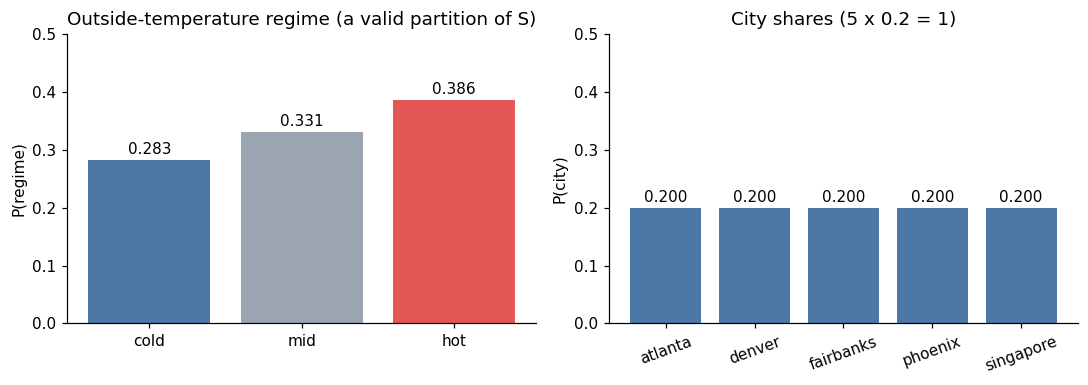

In [25]:
# Chart 1: temperature regime (left) and city shares (right)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(pt.index, pt.values, color=["#4C78A8", "#9AA5B1", "#E45756"])
ax[0].set_title("Outside-temperature regime (a valid partition of S)")
ax[0].set_ylabel("P(regime)"); ax[0].set_ylim(0, 0.5)
for x, v in zip(pt.index, pt.values): ax[0].text(x, v + 0.01, f"{v:.3f}", ha="center")
ax[1].bar(pc.index, pc.values, color="#4C78A8")
ax[1].set_title("City shares (5 x 0.2 = 1)"); ax[1].set_ylabel("P(city)"); ax[1].set_ylim(0, 0.5)
for x, v in zip(pc.index, pc.values): ax[1].text(x, v + 0.01, f"{v:.3f}", ha="center")
plt.setp(ax[1].get_xticklabels(), rotation=20)
plt.tight_layout(); plt.show()

**Interpretation.** The empirical distribution is a valid probability model: every probability is non-negative, the cold/mid/hot shares (0.283 / 0.331 / 0.386) sum to 1, and COLD and HOT share no step, so additivity holds. The same is true for the cities (5 x 0.2) and the floor counts (0.500 / 0.333 / 0.167); these shares are fixed by the design of the file (equal runs per city, 10 runs per building), not discovered from the data. By the complement rule, P(not HP) = 1 - 0.2007 = 0.7993, identical to the direct count: about 4 steps in 5 have a small penalty or none. Penalties are the minority, but they are not spread evenly - Section 5.5 shows they concentrate in occupied steps.

## 5.3 Application 3: Counting techniques (runs and buildings, not steps)
*Textbook: Sec. 2-1.4 (multiplication principle, permutations, combinations)*

**Question.** How many ways can we pick or split the 60 runs, and how likely is a "lucky" selection? Which cells of the design (building x city x policy) actually exist?

**Events and assumptions.** The experiment changes here: the outcomes are *runs* (60 of them) or *buildings* (6), chosen at random **without replacement**. Each run (building) is equally likely to be picked. We compare with the "with replacement" shortcut to show what the finite population changes.

**Rules and why they fit.**
- *Combinations* C(n, k) when order does not matter: a reviewer picks 3 runs to inspect; the probability that all 3 are noisy-policy runs is C(30,3) / C(60,3).
- *Permutations* P(n, k) when order matters: an ordered (train, validation, test) triple of runs.
- *Multiplication principle*: the design has 6 x 5 x 2 cells; the building x weather-file design has 6 x 30 cells.
- Combinations again for *leave-buildings-out* splits.

In [26]:
from math import comb, perm
from itertools import combinations

# --- (a) combinations, without replacement -----------------------------------------
p_3_noisy = comb(30, 3) / comb(60, 3)               # all 3 runs are noisy-policy runs
p_3_noisy_with = 0.5 ** 3                           # same question WITH replacement
p_3_fb   = comb(12, 3) / comb(60, 3)                # all 3 are Fairbanks runs (6 buildings x 2 policies = 12)
p_3_fb_with = 0.2 ** 3
print(f"C(30,3) = {comb(30,3):,}   C(60,3) = {comb(60,3):,}")
print(f"P(3 noisy runs)     = {p_3_noisy:.4f}  vs with replacement {p_3_noisy_with:.4f}")
print(f"P(3 Fairbanks runs) = {p_3_fb:.4f}  vs with replacement {p_3_fb_with:.4f}")

# independent check: list ALL 34,220 triples of runs and count them (brute force)
run_ids   = runs.index.to_list()
is_noisy  = runs.NOISY.to_dict()
is_fb     = (runs.city == "fairbanks").to_dict()
triples   = list(combinations(run_ids, 3))
brute_noisy = sum(all(is_noisy[r] for r in t) for t in triples) / len(triples)
brute_fb    = sum(all(is_fb[r]    for r in t) for t in triples) / len(triples)
print(f"brute force over {len(triples):,} triples: noisy {brute_noisy:.4f} | Fairbanks {brute_fb:.4f}")
assert np.isclose(brute_noisy, p_3_noisy) and np.isclose(brute_fb, p_3_fb)

# complement + disjoint events: the 3 runs contain BOTH policies
# = 1 - P(all noisy) - P(all clean); "all noisy" and "all clean" cannot both happen
p_both_policies = 1 - 2 * p_3_noisy
brute_both = sum(0 < sum(is_noisy[r] for r in t) < 3 for t in triples) / len(triples)
print(f"P(3 runs include both policies) = {p_both_policies:.4f} | brute force {brute_both:.4f}")
assert np.isclose(p_both_policies, brute_both)

C(30,3) = 4,060   C(60,3) = 34,220
P(3 noisy runs)     = 0.1186  vs with replacement 0.1250
P(3 Fairbanks runs) = 0.0064  vs with replacement 0.0080
brute force over 34,220 triples: noisy 0.1186 | Fairbanks 0.0064
P(3 runs include both policies) = 0.7627 | brute force 0.7627


In [27]:
# --- (b) permutations vs combinations ----------------------------------------------
print(f"ordered (train, validation, test) triples: 60P3 = {perm(60,3):,}")
print(f"unordered sets of 3 runs:                 C(60,3) = {comb(60,3):,}")
print(f"ratio = {perm(60,3)//comb(60,3)} = 3! (each set can be ordered 6 ways)")

# --- (c) multiplication principle: the design space ----------------------------------
cells = df.groupby(["building", "city", "policy"]).run_id.nunique()
print(f"\nbuilding x city x policy: {len(cells)} of {6*5*2} cells observed, "
      f"each with exactly one run: {bool(cells.eq(1).all())}")
bw = df.groupby(["building", "weather"]).size()
print(f"building x weather file : {len(bw)} of {6*30} possible pairs exist -> {6*30 - len(bw)} empty cells")
print("buildings per weather file:", df.groupby("weather").building.nunique().unique(),
      "(each weather file is used by exactly one building)")

# --- (d) counting with the building columns -------------------------------------------
print("\nruns per building:", runs.groupby("building").size().unique().tolist())
print("runs per floor count:", runs.groupby("run_n_floors").size().to_dict())
n_big = int(bld.run_n_zones.gt(bld.run_n_zones.median()).sum())     # BIG buildings = 3
p_2big = comb(n_big, 2) / comb(6, 2)
print(f"BIG buildings: {n_big} of 6 | P(both held-out test buildings are BIG) = C(3,2)/C(6,2) = {p_2big:.3f}")
pairs_b = list(combinations(bld.index, 2))
big = bld.run_n_zones.gt(bld.run_n_zones.median()).to_dict()
assert np.isclose(sum(big[a] and big[b] for a, b in pairs_b) / len(pairs_b), p_2big)   # brute-force check

# --- (e) train/test splits ------------------------------------------------------------
print(f"\nhold out 2 test buildings: C(6,2) = {comb(6,2)} ways | leave-one-building-out: {comb(6,1)} splits")
print(f"random 45/15 split of the 60 runs: C(60,15) = {comb(60,15):,}  ({len(str(comb(60,15)))} digits)")

ordered (train, validation, test) triples: 60P3 = 205,320
unordered sets of 3 runs:                 C(60,3) = 34,220
ratio = 6 = 3! (each set can be ordered 6 ways)

building x city x policy: 60 of 60 cells observed, each with exactly one run: True
building x weather file : 30 of 180 possible pairs exist -> 150 empty cells
buildings per weather file: [1] (each weather file is used by exactly one building)

runs per building: [10]
runs per floor count: {2: 30, 3: 20, 4: 10}
BIG buildings: 3 of 6 | P(both held-out test buildings are BIG) = C(3,2)/C(6,2) = 0.200

hold out 2 test buildings: C(6,2) = 15 ways | leave-one-building-out: 6 splits
random 45/15 split of the 60 runs: C(60,15) = 53,194,089,192,720  (14 digits)


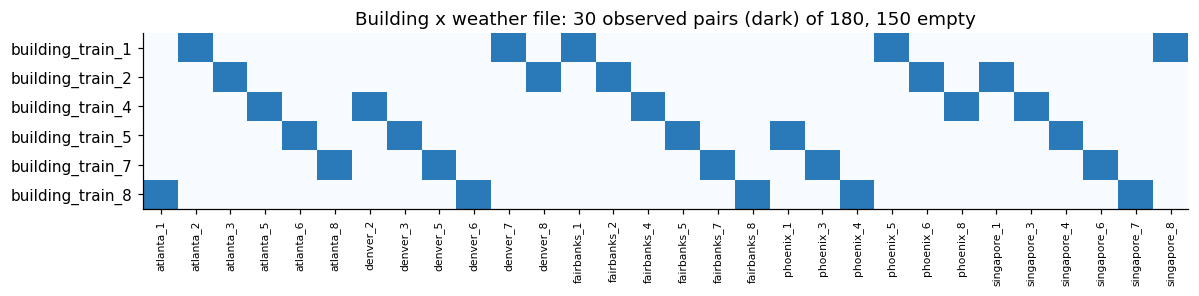

In [28]:
# Chart 2: which (building, weather file) pairs exist? 30 of 180
M = pd.crosstab(df.building, df.weather).gt(0).astype(int)
order = sorted(M.columns, key=lambda w: (w.rsplit("_", 1)[0], int(w.rsplit("_", 1)[1])))
M = M[order]
fig, ax = plt.subplots(figsize=(11, 2.8))
im = ax.imshow(M.values, cmap="Blues", aspect="auto", vmin=0, vmax=1.4)
ax.set_yticks(range(len(M.index))); ax.set_yticklabels(M.index)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.set_title(f"Building x weather file: {int(M.values.sum())} observed pairs (dark) of {M.size}, "
             f"{M.size - int(M.values.sum())} empty")
plt.tight_layout(); plt.show()

**Interpretation.**
- *Finite population.* Choosing 3 of the 60 runs, the chance that all 3 are noisy-policy runs is C(30,3)/C(60,3) = 4,060/34,220 = **0.1186**, a little below the with-replacement value 0.5^3 = 0.125. After one noisy run is drawn there are fewer noisy runs left (29 of 59), so each further draw is slightly less likely to be noisy. The same effect shrinks "3 Fairbanks runs" from 0.0080 to **0.0064**. A brute-force enumeration of all 34,220 triples gives the same numbers, which confirms the formula. By the complement rule, P(the 3 runs include both policies) = 1 - 2 x 0.1186 = 0.7627.
- *Order.* There are 60P3 = 205,320 ordered (train, validation, test) triples but only C(60,3) = 34,220 sets: when only *which* runs are chosen matters (an inspection sample) we use combinations; when the role of each run matters we use permutations.
- *Design space.* All 6 x 5 x 2 = 60 cells exist with exactly one run each, so the design is balanced. The building x weather-file space is different: 6 x 30 = 180 pairs are possible but only 30 exist, because every weather file is used by exactly one building. 150 cells are empty, so we cannot separate "building effect" from "weather-file effect" within a city.
- *Splits.* There are C(6,2) = 15 ways to hold out two test buildings (P(both BIG) = 3/15 = 0.200) and 6 leave-one-building-out splits. A random 45/15 split of runs has C(60,15) = 53,194,089,192,720 possibilities, which is why we fix the seed. A run-level random split puts runs of the *same building* in train and test (leakage), so splitting by building is the honest option for the competition.

## 5.4 Applications 4 and 5: Addition rule and the run-level model
*Textbook: Sec. 2-3 (addition rules)*

### 5.4a Application 4: Addition rule

**Question.** How often is a step either occupied or heavily penalised, and why can we simply add the two temperature extremes?

**Events and assumptions.** OCC (occupancy > 0), HP (reward < -0.1), COLD (< 10 C), HOT (> 25 C). Steps are equally likely.

**Rules and why they fit.**
- *General addition rule*: P(A or B) = P(A) + P(B) - P(A and B). OCC and HP overlap (a step can be both), so the overlap must be subtracted or it would be counted twice.
- *Mutually exclusive case*: P(A or B) = P(A) + P(B). COLD and HOT cannot happen together because one outside temperature cannot be both below 283.15 K and above 298.15 K, so the intersection is empty and nothing is subtracted.

In [29]:
pO, pH, pOH = df.OCC.mean(), df.HP.mean(), (df.OCC & df.HP).mean()
p_or_rule   = pO + pH - pOH                         # general addition rule
p_or_direct = (df.OCC | df.HP).mean()               # direct count of the union
print(f"P(OCC) = {pO:.4f}   P(HP) = {pH:.4f}   P(OCC and HP) = {pOH:.4f}")
print(f"P(OCC or HP): rule = {p_or_rule:.4f} | direct = {p_or_direct:.4f}")
print(f"if we forgot the overlap: {pO + pH:.4f}  (too high)")
print(f"share of HP steps that are also OCC = {pOH / pH:.4f}")
assert np.isclose(p_or_rule, p_or_direct)

# mutually exclusive case
pC, pT = df.COLD.mean(), df.HOT.mean()
print(f"\nP(COLD or HOT): rule = {pC + pT:.4f} | direct = {(df.COLD | df.HOT).mean():.4f} "
      f"| steps in both = {int((df.COLD & df.HOT).sum())}")
assert np.isclose(pC + pT, (df.COLD | df.HOT).mean())

P(OCC) = 0.3735   P(HP) = 0.2007   P(OCC and HP) = 0.1878
P(OCC or HP): rule = 0.3863 | direct = 0.3863
if we forgot the overlap: 0.5742  (too high)
share of HP steps that are also OCC = 0.9360

P(COLD or HOT): rule = 0.6693 | direct = 0.6693 | steps in both = 0


**Interpretation.** A step is occupied or heavily penalised in **38.6%** of cases (0.3735 + 0.2007 - 0.1878 = 0.3863); ignoring the overlap would give 0.574, which is wrong. The overlap 0.1878 is 93.6% of P(HP): almost every heavily penalised step happens while people are present (Section 5.8 formalises this with Bayes' theorem). For outside temperature, P(COLD or HOT) = 0.2832 + 0.3861 = **0.6693** with no subtraction, because the two events are mutually exclusive; the remaining 33% are mild (10-25 C) steps.

### 5.4a-ii Addition rule for three events, Venn regions and De Morgan's laws
*Textbook: Sec. 2-3 (addition rules), Sec. 2-1.3 (unions, intersections, complements, De Morgan)*

**Question.** How often is a step occupied, or heavily penalised, or expensive in electricity (HE = cost in the top 25%)? And can the same answer be reached by looking at what is *outside* these events?

**Events and assumptions.** A = OCC, B = HP, C = HE, all subsets of the same 241,920 equally likely time steps. The three events overlap, so none of the simple cases applies.

**Rules and why they fit.**
- *Addition rule for three events (inclusion-exclusion):* P(A or B or C) = P(A) + P(B) + P(C) - P(A and B) - P(A and C) - P(B and C) + P(A and B and C). Adding the three probabilities counts steps in two events twice and steps in all three three times; the pair terms remove the double counts, but they also remove the triple overlap one time too many, so it is added back once.
- *Venn regions:* OCC and HP split S into four disjoint regions (OCC only, both, HP only, neither) whose probabilities sum to 1.
- *De Morgan's laws:* (A or B)' = A' and B', and (A and B)' = A' or B'. They link the union to the complement, so P(A or B) = 1 - P(A' and B').

In [30]:
# Three-event addition rule: occ3 = OCC, hp3 = HP, he3 = HE (high electricity cost)
occ3, hp3, he3 = df.OCC, df.HP, df.HE
share = lambda e: e.mean()                               # P(event) = share of steps in the event
s_o, s_h, s_e = share(occ3), share(hp3), share(he3)
s_oh, s_oe, s_he = share(occ3 & hp3), share(occ3 & he3), share(hp3 & he3)
s_ohe = share(occ3 & hp3 & he3)

rule3   = s_o + s_h + s_e - s_oh - s_oe - s_he + s_ohe   # inclusion-exclusion
direct3 = share(occ3 | hp3 | he3)                        # direct count of the union
naive3  = s_o + s_h + s_e                                # forgetting the overlaps
print(f"P(OCC) = {s_o:.4f}  P(HP) = {s_h:.4f}  P(HE) = {s_e:.4f}")
print(f"pairs: P(OCC,HP) = {s_oh:.4f}  P(OCC,HE) = {s_oe:.4f}  P(HP,HE) = {s_he:.4f}  | triple = {s_ohe:.4f}")
print(f"P(OCC or HP or HE): rule = {rule3:.4f} | direct = {direct3:.4f} | no overlaps removed = {naive3:.4f} (too high)")
assert np.isclose(rule3, direct3)

# Venn regions of OCC and HP: four disjoint events that partition S
reg = pd.Series({"OCC only": (occ3 & ~hp3).sum(), "OCC and HP": (occ3 & hp3).sum(),
                 "HP only": (~occ3 & hp3).sum(), "neither": (~occ3 & ~hp3).sum()})
venn = pd.DataFrame({"steps": reg, "probability": reg / len(df)})
assert reg.sum() == len(df) and np.isclose(venn.probability.sum(), 1.0)
display(venn.round(4))

# De Morgan's laws, checked step by step (the two sides must be the same set of steps)
dm1 = bool((~(occ3 | hp3) == (~occ3 & ~hp3)).all())      # (A or B)' = A' and B'
dm2 = bool((~(occ3 & hp3) == (~occ3 | ~hp3)).all())      # (A and B)' = A' or B'
p_neither = share(~occ3 & ~hp3)
print(f"\nDe Morgan 1: (OCC or HP)' = (not OCC) and (not HP) for every step: {dm1}")
print(f"De Morgan 2: (OCC and HP)' = (not OCC) or (not HP)  for every step: {dm2}")
print(f"P(OCC or HP) = 1 - P(not OCC and not HP) = 1 - {p_neither:.4f} = {1 - p_neither:.4f}  (5.4a result: {share(occ3 | hp3):.4f})")
assert dm1 and dm2 and np.isclose(1 - p_neither, share(occ3 | hp3))

P(OCC) = 0.3735  P(HP) = 0.2007  P(HE) = 0.2500
pairs: P(OCC,HP) = 0.1878  P(OCC,HE) = 0.1891  P(HP,HE) = 0.1270  | triple = 0.1149
P(OCC or HP or HE): rule = 0.4351 | direct = 0.4351 | no overlaps removed = 0.8242 (too high)


,steps,probability
OCC only,44910,0.1856
OCC and HP,45442,0.1878
HP only,3108,0.0128
neither,148460,0.6137



De Morgan 1: (OCC or HP)' = (not OCC) and (not HP) for every step: True
De Morgan 2: (OCC and HP)' = (not OCC) or (not HP)  for every step: True
P(OCC or HP) = 1 - P(not OCC and not HP) = 1 - 0.6137 = 0.3863  (5.4a result: 0.3863)


**Interpretation.** A step is occupied, heavily penalised or high-cost in **43.5%** of cases. The rule and the direct count agree, while simply adding the three probabilities gives 0.824, which cannot be right because the events overlap strongly: P(OCC and HE) = 0.189 is almost as large as P(HE) = 0.25, so about three quarters of the high-electricity-cost steps are occupied (P(HE | OCC) = 0.506 against 0.25 overall). The Venn table shows the same structure from the other side: 61.4% of steps are in none of OCC or HP, and only 3,108 steps (1.3%) are penalised while the building is empty. De Morgan's laws hold for every step, so P(OCC or HP) = 1 - P(neither) = 0.386, the same number as in 5.4a reached through the complement. The union is easiest to compute through its complement when the event "none of these" is simple to describe.

### 5.4b Application 5: `done` and the run-level model

**Question.** A natural extra outcome for a control run would be "the episode ends early" (the `done` flag). Does that concept apply, and if not, what is a meaningful alternative?

**Why the direct concept does not apply.** `done` is 0 in every row, so P(episode ends) = 0 exactly and there is no event to model. We say this explicitly and use an alternative.

**Alternative: runs as the sample space.** Take the 60 runs as outcomes (equally likely) and use the run-level score `run_mean_reward` from the 60-row `runs` table (never averaged over rows, which would count each run 4,032 times).
- Event BAD_RUN = {`run_mean_reward` below the median of the 60 runs}. By construction P(BAD_RUN) = 30/60 = 0.5.
- Event NOISY = noisy-policy run. We compare P(BAD_RUN | NOISY) with P(BAD_RUN | clean) using counts of runs.
- A paired check: in each of the 30 (building, weather) pairs, does the noisy run score lower than its clean twin?
- The step-based quantity p_run = P(HP | OCC) per run (share of occupied steps that are heavily penalised), to see how much a single pooled probability hides.

**Assumption.** Runs are treated as equally likely; there are only 60 of them, so every run-level probability is a multiple of 1/60.

In [31]:
# Step-level fact: done never happens
print("P(done = 1) =", df_raw.done.mean(), "| distinct values of done:", df_raw.done.unique())

# Run-level sample space: 60 runs
rm = runs.run_mean_reward
med = rm.median()
print(f"\nmedian run_mean_reward = {med:.4f} | BAD_RUN runs = {int(runs.BAD_RUN.sum())} of {len(runs)} "
      f"-> P(BAD_RUN) = {runs.BAD_RUN.mean():.3f}")
assert np.isclose(med, -0.0447, atol=1e-4)

n_bad_noisy = int(runs[runs.NOISY].BAD_RUN.sum());  n_bad_clean = int(runs[~runs.NOISY].BAD_RUN.sum())
print(f"P(BAD_RUN | noisy) = {n_bad_noisy}/30 = {n_bad_noisy/30:.3f}")
print(f"P(BAD_RUN | clean) = {n_bad_clean}/30 = {n_bad_clean/30:.3f}")
print("check with groupby:", runs.groupby("NOISY").BAD_RUN.mean().round(3).to_dict())

# paired comparison: noisy twin worse than clean twin?
pv = runs.pivot_table(index="pair_id", columns="policy", values="run_mean_reward")
n_worse = int((pv.noisy_pid_water < pv.pid_water).sum())
print(f"\nnoisy run has the lower run_mean_reward in {n_worse} of {len(pv)} pairs ({n_worse/len(pv):.3f})")

# best and worst runs
print(f"best  run: {rm.idxmax()}  ({rm.max():.3f})")
print(f"worst run: {rm.idxmin()}  ({rm.min():.3f})")

# step-based quantity per run: p_run = P(HP | OCC) within each run
p_run = df[df.OCC].groupby("run_id").HP.mean()
print("\np_run = P(HP | OCC) per run:"); print(p_run.describe().round(3).to_string())
print(f"pooled P(HP | OCC) over all steps = {(df.OCC & df.HP).sum() / df.OCC.sum():.4f}")

P(done = 1) = 0.0 | distinct values of done: [0]

median run_mean_reward = -0.0447 | BAD_RUN runs = 30 of 60 -> P(BAD_RUN) = 0.500
P(BAD_RUN | noisy) = 19/30 = 0.633
P(BAD_RUN | clean) = 11/30 = 0.367
check with groupby: {False: 0.367, True: 0.633}

noisy run has the lower run_mean_reward in 27 of 30 pairs (0.900)
best  run: building_train_5__fairbanks_5__pid_water  (-0.016)
worst run: building_train_1__fairbanks_1__pid_water  (-0.301)

p_run = P(HP | OCC) per run:
count    60.000
mean      0.506
std       0.303
min       0.000
25%       0.242
50%       0.506
75%       0.774
max       0.999
pooled P(HP | OCC) over all steps = 0.5029


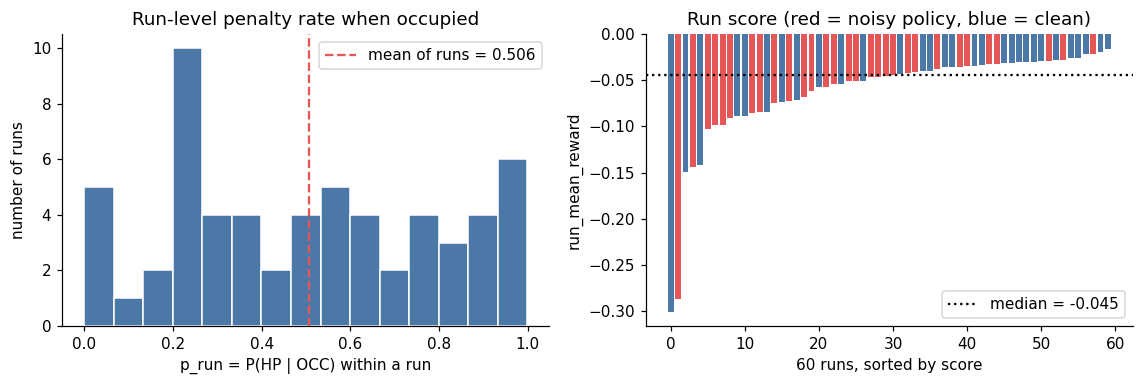

In [32]:
# Chart 3: one pooled probability hides large run-to-run variation
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].hist(p_run, bins=15, color="#4C78A8", edgecolor="white")
ax[0].axvline(p_run.mean(), color="#E45756", ls="--", label=f"mean of runs = {p_run.mean():.3f}")
ax[0].set_xlabel("p_run = P(HP | OCC) within a run"); ax[0].set_ylabel("number of runs")
ax[0].set_title("Run-level penalty rate when occupied"); ax[0].legend()

colors = runs.NOISY.map({True: "#E45756", False: "#4C78A8"})
order_r = rm.sort_values().index
ax[1].bar(range(len(order_r)), rm[order_r], color=colors[order_r])
ax[1].axhline(med, color="black", ls=":", label=f"median = {med:.3f}")
ax[1].set_xlabel("60 runs, sorted by score"); ax[1].set_ylabel("run_mean_reward")
ax[1].set_title("Run score (red = noisy policy, blue = clean)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.**
- *`done` gives nothing to model*: no run ever terminates, so P(episode ends) = 0. The honest replacement is to study the *run score*.
- *Policy matters at run level.* Of the 30 runs scoring below the median, 19 are noisy-policy runs: P(BAD_RUN | noisy) = 19/30 = **0.633** against P(BAD_RUN | clean) = 11/30 = **0.367**. In a like-for-like comparison (same building and weather), the noisy run scores lower than its clean twin in **27 of 30 pairs (0.900)**.
- *But policy alone does not decide a run.* The scores span from -0.016 (building_train_5, fairbanks_5, clean policy, the best) to -0.301 (building_train_1, fairbanks_1, clean policy, the worst). Both extremes are *clean-policy Fairbanks* runs, so building and weather can outweigh the policy.
- *A pooled probability hides this spread.* p_run = P(HP | OCC) runs from 0.000 to 0.999 across the 60 runs (mean 0.506, close to the pooled 0.503; the two differ slightly because runs have different numbers of occupied steps). This motivates the run-level validation in Section 6.4: the honest uncertainty comes from having only 60 runs, not 241,920 rows.

## 5.4c Hand-over: stored results of Sections 5.1-5.4 for the validation
The dictionary `res_M2` holds the rule-based results, computed live from the variables above, so Section 6 can place them in the three-way validation table without retyping numbers.

In [33]:
res_M2 = {
    "P(OCC)":                 p_occ,
    "P(not OCC)":             1 - p_occ,
    "P(OCC | weekend)":       p_occ_weekend,
    "P(OCC | weekday 6-18)":  p_occ_workhrs,
    "P(COLD)":                df.COLD.mean(),
    "P(MID)":                 pt["mid"],
    "P(HOT)":                 df.HOT.mean(),
    "P(not HP) complement":   1 - p_hp,
    "P(OCC or HP) addition":  p_or_rule,
    "P(COLD or HOT) addition": pC + pT,
    "P(3 noisy runs) C(30,3)/C(60,3)": p_3_noisy,
    "P(3 Fairbanks runs) C(12,3)/C(60,3)": p_3_fb,
    "P(both held-out buildings BIG)": p_2big,
    "P(BAD_RUN | noisy)":     n_bad_noisy / 30,
    "P(BAD_RUN | clean)":     n_bad_clean / 30,
    "noisy worse in pairs":   n_worse / len(pv),
    "mean p_run":             p_run.mean(),
}
# direct-count twins for the validation table (a second route that needs no formula)
res_M2_direct = {
    "P(OCC)":                 df.OCC.sum() / len(df),
    "P(not HP) complement":   (~df.HP).sum() / len(df),
    "P(OCC or HP) addition":  (df.OCC | df.HP).sum() / len(df),
    "P(COLD or HOT) addition": (df.COLD | df.HOT).sum() / len(df),
    "P(3 noisy runs) C(30,3)/C(60,3)": brute_noisy,
    "P(3 Fairbanks runs) C(12,3)/C(60,3)": brute_fb,
}
chk2 = pd.DataFrame({"rule": {k: res_M2[k] for k in res_M2_direct}, "direct": res_M2_direct})
chk2["|rule - direct|"] = (chk2.rule - chk2.direct).abs()
display(chk2.round(6))
assert (chk2["|rule - direct|"] < 1e-12).all()      # same finite population -> exact agreement
pd.Series(res_M2, name="value").round(4).to_frame()

,rule,direct,|rule - direct|
P(OCC),0.373479,0.373479,0.0
P(not HP) complement,0.799314,0.799314,0.0
P(OCC or HP) addition,0.386326,0.386326,0.0
P(COLD or HOT) addition,0.669254,0.669254,0.0
"P(3 noisy runs) C(30,3)/C(60,3)",0.118644,0.118644,0.0
"P(3 Fairbanks runs) C(12,3)/C(60,3)",0.006429,0.006429,0.0


,value
P(OCC),0.3735
P(not OCC),0.6265
P(OCC | weekend),0.0000
P(OCC | weekday 6-18),0.9653
P(COLD),0.2832
P(MID),0.3307
P(HOT),0.3861
P(not HP) complement,0.7993
P(OCC or HP) addition,0.3863
P(COLD or HOT) addition,0.6693


**Exact agreement.** The rule-based and direct-count routes use the same finite population of steps (or the same list of runs), so they agree to rounding error (differences below 1e-12). Any difference would signal a bug. Differences in *uncertainty* only appear later, in the block bootstrap of Section 6.4.

## 5.5 Application 6: Conditional probability (who gets penalised, and when?)
*Textbook: Sec. 2-4 (conditional probability)*

**Question.** Are heavily penalised steps mainly an occupied-building phenomenon, and do cold weather or building size change that?

**Events and assumptions.** OCC (occupancy > 0), HP (reward < -0.1), COLD (outside air < 10 C), BIG (more than 46.5 zones: buildings 2, 4, 5). The experiment is the usual one: pick one of the 241,920 time steps at random, all equally likely. The steps are not independent observations, so every result is a relative frequency over these 60 runs.

**Rule and why it fits.** For equally likely outcomes, P(A | B) = P(A and B) / P(B) = |A and B| / |B|: once we know B happened, the sample space shrinks from S to B. This is the right tool because the question is "given people are present, how often is the reward low?". We write both directions in words next to every number, because P(HP | OCC) and P(OCC | HP) answer different questions (the second one is Bayes, Application 9).

In [34]:
def Pc(a, b):
    '''P(a | b) for two Boolean Series: |a and b| / |b| (b = the condition).'''
    return (a & b).sum() / b.sum()

p_hp_all  = df.HP.mean()
p_hp_occ  = Pc(df.HP, df.OCC)          # P(HP | occupied)
p_hp_nocc = Pc(df.HP, ~df.OCC)         # P(HP | empty)
print(f"P(HP)            = {p_hp_all:.4f}")
print(f"P(HP | OCC)      = {p_hp_occ:.4f}   (given people are present)")
print(f"P(HP | not OCC)  = {p_hp_nocc:.4f}   (given the building is empty)")
print(f"ratio            = {p_hp_occ / p_hp_nocc:.1f}x")

# independent route: groupby mean (no formula)
gb = df.groupby("OCC").HP.mean()
assert np.isclose(gb[True], p_hp_occ) and np.isclose(gb[False], p_hp_nocc)

# second condition: occupied AND cold vs occupied AND not cold
p_hp_oc  = Pc(df.HP, df.OCC & df.COLD)
p_hp_onc = Pc(df.HP, df.OCC & ~df.COLD)
print(f"\nP(HP | OCC and COLD)     = {p_hp_oc:.4f}")
print(f"P(HP | OCC and not COLD) = {p_hp_onc:.4f}")

# building size (3 big vs 3 small buildings)
p_hp_big, p_hp_nbig = Pc(df.HP, df.BIG), Pc(df.HP, ~df.BIG)
p_hp_occ_big, p_hp_occ_nbig = Pc(df.HP, df.OCC & df.BIG), Pc(df.HP, df.OCC & ~df.BIG)
print(f"\nP(HP | BIG) = {p_hp_big:.4f}  vs  P(HP | not BIG) = {p_hp_nbig:.4f}")
print(f"among occupied steps: BIG {p_hp_occ_big:.3f}  vs  not BIG {p_hp_occ_nbig:.3f}")

# building table (6 rows, 10 runs each)
bld_tab = df.groupby("building").agg(zones=("run_n_zones", "first"), floors=("run_n_floors", "first"),
                                     P_HP=("HP", "mean"))
bld_tab["P_HP_given_OCC"] = df[df.OCC].groupby("building").HP.mean()
bld_tab.round(3).sort_values("zones")

P(HP)            = 0.2007
P(HP | OCC)      = 0.5029   (given people are present)
P(HP | not OCC)  = 0.0205   (given the building is empty)
ratio            = 24.5x

P(HP | OCC and COLD)     = 0.7499
P(HP | OCC and not COLD) = 0.4380

P(HP | BIG) = 0.1795  vs  P(HP | not BIG) = 0.2219
among occupied steps: BIG 0.473  vs  not BIG 0.533


,zones,floors,P_HP,P_HP_given_OCC
building,,,,
building_train_8,30,2,0.197,0.491
building_train_7,36,2,0.208,0.570
building_train_1,39,3,0.260,0.540
building_train_4,54,3,0.165,0.434
building_train_5,79,4,0.171,0.442
building_train_2,85,2,0.203,0.545


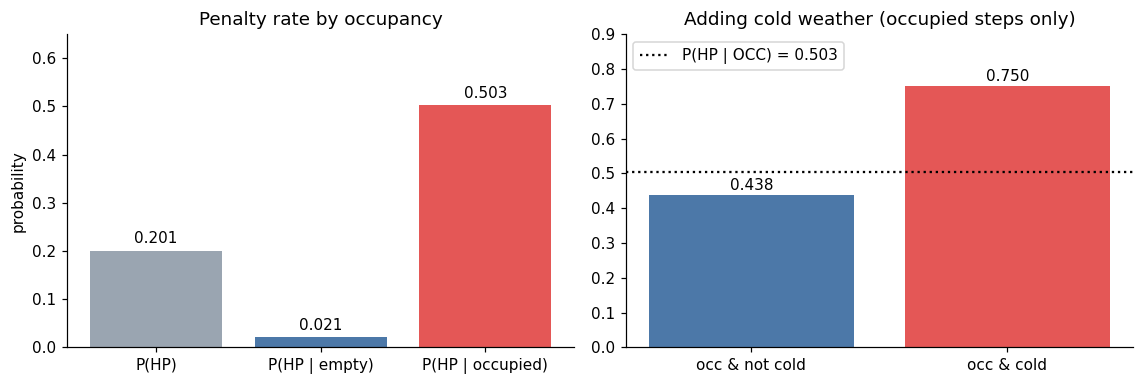

In [35]:
# Chart 4: conditioning changes the probability
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
lab = ["P(HP)", "P(HP | empty)", "P(HP | occupied)"]
val = [p_hp_all, p_hp_nocc, p_hp_occ]
ax[0].bar(lab, val, color=["#9AA5B1", "#4C78A8", "#E45756"])
for x, v in zip(lab, val): ax[0].text(x, v + 0.015, f"{v:.3f}", ha="center")
ax[0].set_ylim(0, 0.65); ax[0].set_ylabel("probability"); ax[0].set_title("Penalty rate by occupancy")
lab2 = ["occ & not cold", "occ & cold"]; val2 = [p_hp_onc, p_hp_oc]
ax[1].bar(lab2, val2, color=["#4C78A8", "#E45756"])
for x, v in zip(lab2, val2): ax[1].text(x, v + 0.015, f"{v:.3f}", ha="center")
ax[1].axhline(p_hp_occ, color="black", ls=":", label=f"P(HP | OCC) = {p_hp_occ:.3f}")
ax[1].set_ylim(0, 0.9); ax[1].set_title("Adding cold weather (occupied steps only)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.** When people are present, about half of all steps (0.503) are heavily penalised; when the building is empty only 0.021 are. Occupancy raises the penalty chance about 25 times, and the unconditional P(HP) = 0.2007 is just a weighted mix of these two very different rates. Among occupied steps, cold weather pushes the rate from 0.438 to 0.750: occupied *and* cold is the hardest situation for the baseline controllers.

*Building size* goes against the intuitive guess: big buildings are penalised **less** (0.179 vs 0.222; occupied steps 0.473 vs 0.533). With only 3 big and 3 small buildings, and building identity confounded with size, this is a statement about these six buildings, not an effect of size. These are associations in simulated data: the reward is built from occupancy-weighted productivity terms, so the link with occupancy is partly by design.

## 5.6 Application 7: Multiplication rule and the chain rule
*Textbook: Sec. 2-5 (multiplication rule)*

**Question.** How many steps are occupied *and* heavily penalised, and how rare is the combination occupied, cold and heavily penalised?

**Events and assumptions.** OCC, HP, COLD as before; same equally likely time steps.

**Rule and why it fits.** The multiplication rule rewrites a joint probability as a marginal times a conditional: P(A and B) = P(A) P(B | A). For three events we chain it: P(A and B and C) = P(A) P(B | A) P(C | A and B). It fits because conditional probabilities are what we can read off the dataset easily (Application 6), and the joint event is what we want. We check each product against a direct count of the intersection.

In [36]:
# two events: P(OCC and HP) = P(OCC) P(HP | OCC)
p_occ_m3     = df.OCC.mean()
p_and_rule   = p_occ_m3 * p_hp_occ
p_and_direct = (df.OCC & df.HP).mean()
print(f"P(OCC) x P(HP|OCC) = {p_occ_m3:.4f} x {p_hp_occ:.4f} = {p_and_rule:.4f} | direct = {p_and_direct:.4f}")
assert np.isclose(p_and_rule, p_and_direct)
# the same joint event in the other order: P(HP) P(OCC | HP)
print(f"P(HP) x P(OCC|HP)  = {p_hp_all:.4f} x {Pc(df.OCC, df.HP):.4f} = {p_hp_all * Pc(df.OCC, df.HP):.4f}")

# three events (chain rule): P(OCC and COLD and HP)
p_cold_occ     = Pc(df.COLD, df.OCC)                      # P(COLD | OCC)
p_chain_rule   = p_occ_m3 * p_cold_occ * p_hp_oc
p_chain_direct = (df.OCC & df.COLD & df.HP).mean()
print(f"\nP(OCC) x P(COLD|OCC) x P(HP|OCC,COLD) = {p_occ_m3:.4f} x {p_cold_occ:.4f} x {p_hp_oc:.4f} = {p_chain_rule:.4f}")
print(f"direct count of (OCC & COLD & HP)                  = {p_chain_direct:.4f}   (about 1 step in {1/p_chain_direct:.0f})")
assert np.isclose(p_chain_rule, p_chain_direct)

P(OCC) x P(HP|OCC) = 0.3735 x 0.5029 = 0.1878 | direct = 0.1878
P(HP) x P(OCC|HP)  = 0.2007 x 0.9360 = 0.1878

P(OCC) x P(COLD|OCC) x P(HP|OCC,COLD) = 0.3735 x 0.2082 x 0.7499 = 0.0583
direct count of (OCC & COLD & HP)                  = 0.0583   (about 1 step in 17)


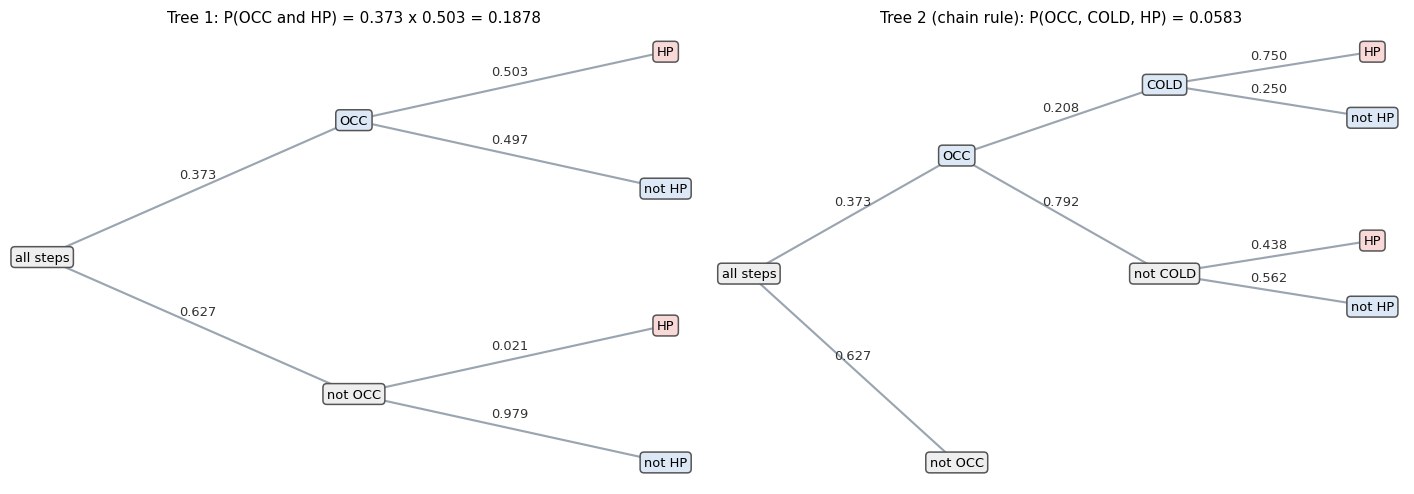

In [37]:
# Probability trees (the numbers on the branches are live conditional probabilities)
def draw_tree(ax, nodes, edges, title):
    for (x0, y0, x1, y1, lab) in edges:
        ax.plot([x0, x1], [y0, y1], color="#9AA5B1", lw=1.4, zorder=1)
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.02, lab, ha="center", fontsize=8.5, color="#333333")
    for (x, y, t, c) in nodes:
        ax.text(x, y, t, ha="center", va="center", fontsize=8.5, zorder=2,
                bbox=dict(boxstyle="round,pad=0.3", fc=c, ec="#555555"))
    ax.set_title(title, fontsize=10); ax.axis("off")

blue, red, grey = "#DCE8F5", "#F8D9D8", "#EEEEEE"
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
# tree 1: OCC -> HP
n1 = [(0, .5, "all steps", grey), (1, .75, "OCC", blue), (1, .25, "not OCC", grey),
      (2, .875, "HP", red), (2, .625, "not HP", blue), (2, .375, "HP", red), (2, .125, "not HP", blue)]
e1 = [(0, .5, 1, .75, f"{p_occ_m3:.3f}"), (0, .5, 1, .25, f"{1 - p_occ_m3:.3f}"),
      (1, .75, 2, .875, f"{p_hp_occ:.3f}"), (1, .75, 2, .625, f"{1 - p_hp_occ:.3f}"),
      (1, .25, 2, .375, f"{p_hp_nocc:.3f}"), (1, .25, 2, .125, f"{1 - p_hp_nocc:.3f}")]
draw_tree(ax[0], n1, e1, f"Tree 1: P(OCC and HP) = {p_occ_m3:.3f} x {p_hp_occ:.3f} = {p_and_rule:.4f}")
# tree 2: OCC -> COLD -> HP (chain rule)
n2 = [(0, .5, "all steps", grey), (1, .75, "OCC", blue), (1, .1, "not OCC", grey),
      (2, .9, "COLD", blue), (2, .5, "not COLD", grey),
      (3, .97, "HP", red), (3, .83, "not HP", blue), (3, .57, "HP", red), (3, .43, "not HP", blue)]
e2 = [(0, .5, 1, .75, f"{p_occ_m3:.3f}"), (0, .5, 1, .1, f"{1 - p_occ_m3:.3f}"),
      (1, .75, 2, .9, f"{p_cold_occ:.3f}"), (1, .75, 2, .5, f"{1 - p_cold_occ:.3f}"),
      (2, .9, 3, .97, f"{p_hp_oc:.3f}"), (2, .9, 3, .83, f"{1 - p_hp_oc:.3f}"),
      (2, .5, 3, .57, f"{p_hp_onc:.3f}"), (2, .5, 3, .43, f"{1 - p_hp_onc:.3f}")]
draw_tree(ax[1], n2, e2, f"Tree 2 (chain rule): P(OCC, COLD, HP) = {p_chain_rule:.4f}")
plt.tight_layout(); plt.show()

**Interpretation.** P(OCC and HP) = 0.3735 x 0.5029 = **0.1878**, exactly the direct count; multiplying along a branch of Tree 1 gives the joint probability, and adding the two HP leaves (0.1878 + 0.6265 x 0.0205 = 0.2007) gives P(HP) - this is the total-probability rule of the next application seen as a tree. The chain rule gives P(OCC and COLD and HP) = 0.3735 x 0.2082 x 0.7499 = **0.0583**, equal to the direct count: about 1 step in 17 is occupied, cold and heavily penalised, although only 21% of occupied steps are cold, because cold steps are penalised so often.

## 5.7 Application 8: Total probability
*Textbook: Sec. 2-5 (total probability rule)*

**Question.** Can we recover the overall penalty probability P(HP) from group-level rates alone, and which groups carry the risk?

**Events and assumptions.** A *partition* is a set of mutually exclusive events that together cover S. We use four: the 5 cities, the 2 policies, the 3 floor counts (F2, F3, F4) and the 6 buildings. All of them are fixed by the design of the file (equal numbers of runs), so the weights P(group) are known exactly.

**Rule and why it fits.** If B1, ..., Bk partition S, then P(HP) = sum over i of P(HP | Bi) P(Bi). It fits because group-level penalty rates are what an organiser would report per scenario, and the rule shows how they combine into one number; it is also the **denominator of Bayes' theorem** in Application 9. We compare each partition with the direct P(HP): they must agree exactly.

In [38]:
def total_prob(labels, event):
    '''Total probability over a partition given by `labels`: sum_i P(event | group i) P(group i).'''
    w = labels.value_counts(normalize=True)                  # P(group)
    r = event.groupby(labels).mean()                         # P(event | group)
    return (w * r).sum(), w, r

parts = {"city": df.city, "policy": df.policy, "floors": df.run_n_floors, "building": df.building}
rows = []
for name, lab in parts.items():
    tp, w, r = total_prob(lab, df.HP)
    rows.append((name, len(w), tp, p_hp_all, abs(tp - p_hp_all)))
    assert np.isclose(tp, p_hp_all)
tp_tab = pd.DataFrame(rows, columns=["partition", "groups", "total probability", "direct P(HP)", "|difference|"])
display(tp_tab.round(6))

# the city partition in detail (and the numbers used later as Bayes priors / likelihoods)
tp_city, w_city, r_city = total_prob(df.city, df.HP)
city_tab = pd.DataFrame({"P(city)": w_city, "P(HP|city)": r_city, "product": w_city * r_city}).round(4)
print("sum of products =", round(city_tab["product"].sum(), 4)); display(city_tab)
tp_pol, w_pol, r_pol = total_prob(df.policy, df.HP)
tp_fl,  w_fl,  r_fl  = total_prob(df.run_n_floors, df.HP)
print("policy:", r_pol.round(4).to_dict(), "| floors:", r_fl.round(4).to_dict())

,partition,groups,total probability,direct P(HP),|difference|
0,city,5,0.200686,0.200686,0.0
1,policy,2,0.200686,0.200686,0.0
2,floors,3,0.200686,0.200686,0.0
3,building,6,0.200686,0.200686,0.0


sum of products = 0.2006


,P(city),P(HP|city),product
city,,,
atlanta,0.2,0.1322,0.0264
denver,0.2,0.1549,0.0310
fairbanks,0.2,0.2726,0.0545
phoenix,0.2,0.2472,0.0494
singapore,0.2,0.1966,0.0393


policy: {'noisy_pid_water': 0.2272, 'pid_water': 0.1742} | floors: {2: 0.2027, 3: 0.2126, 4: 0.1708}


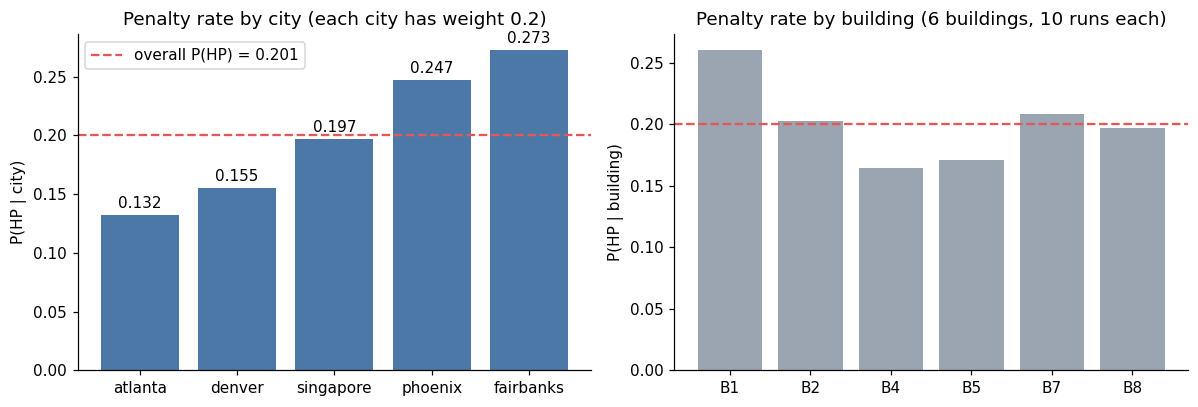

In [39]:
# Chart 5: penalty rate by city and by building
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
c_ord = r_city.sort_values()
ax[0].bar(c_ord.index, c_ord.values, color="#4C78A8")
ax[0].axhline(p_hp_all, color="#E45756", ls="--", label=f"overall P(HP) = {p_hp_all:.3f}")
for x, v in zip(c_ord.index, c_ord.values): ax[0].text(x, v + 0.006, f"{v:.3f}", ha="center")
ax[0].set_ylabel("P(HP | city)"); ax[0].set_title("Penalty rate by city (each city has weight 0.2)"); ax[0].legend()
_, _, r_b = total_prob(df.building, df.HP)
ax[1].bar([b.replace("building_train_", "B") for b in r_b.index], r_b.values, color="#9AA5B1")
ax[1].axhline(p_hp_all, color="#E45756", ls="--")
ax[1].set_ylabel("P(HP | building)"); ax[1].set_title("Penalty rate by building (6 buildings, 10 runs each)")
plt.tight_layout(); plt.show()

**Interpretation.** All four partitions reproduce P(HP) = 0.2007 exactly (cities: 0.2 x (0.1322 + 0.1549 + 0.2726 + 0.2472 + 0.1966); policies: 0.5 x 0.2272 + 0.5 x 0.1742; floors: 0.5 x 0.2027 + 0.3333 x 0.2126 + 0.1667 x 0.1708), so the model is consistent: the overall rate is simply the weighted average of the group rates.

The groups reveal where the risk sits. **Fairbanks (0.273) and Phoenix (0.247)**, the two extreme climates, are penalised about twice as often as Atlanta (0.132). The noisy policy has the higher rate (0.227 vs 0.174). Across buildings the rate runs from 0.165 (building_train_4) to 0.260 (building_train_1), and the only 4-floor building is among the lowest (0.171): more floors does not mean more penalties. Because each building has its own weather files, building and weather effects cannot be fully separated (Section 5.3).

## 5.8 Application 9: Bayes' theorem
*Textbook: Sec. 2-7 (Bayes' theorem)*

**Question.** A step is observed to be heavily penalised. What does that tell us about the *situation*: was the building occupied, which policy was running, in which city are we, and in what kind of building?

**Events and assumptions.** Hypotheses H: OCC, NOISY, each city, F4, BIG. Evidence E: HP. Priors P(H) are the shares of steps; likelihoods P(HP | H) come from Applications 6 and 8. At run level the evidence is BAD_RUN (run score below the median) and the experiment changes to *runs* (60 outcomes). Same equally likely assumption.

**Rule and why it fits.** Bayes' theorem reverses a conditional: P(H | E) = P(E | H) P(H) / P(E), where the denominator P(E) = sum of P(E | Hi) P(Hi) is the total probability of Application 8. It fits because the data naturally give "penalty rate in each situation", while an analyst who sees a penalty wants "how likely is each situation". We verify every posterior against the direct count |H and E| / |E|.

In [40]:
def bayes(lik, prior, evidence):
    '''P(H | E) = P(E | H) P(H) / P(E).'''
    return lik * prior / evidence

# A) occupancy and B) policy
post_occ   = bayes(p_hp_occ, df.OCC.mean(), p_hp_all);   dir_occ   = Pc(df.OCC, df.HP)
p_hp_noisy = Pc(df.HP, df.NOISY)
post_noisy = bayes(p_hp_noisy, df.NOISY.mean(), p_hp_all); dir_noisy = Pc(df.NOISY, df.HP)
print(f"A) P(OCC | HP)   = {post_occ:.4f}  (direct {dir_occ:.4f})  prior {df.OCC.mean():.4f}")
print(f"B) P(NOISY | HP) = {post_noisy:.4f}  (direct {dir_noisy:.4f})  prior {df.NOISY.mean():.4f}")
assert np.isclose(post_occ, dir_occ) and np.isclose(post_noisy, dir_noisy)

# C) city posterior table (priors 0.2 each; denominator = total probability from 5.7)
post_city = bayes(r_city, w_city, tp_city)
dir_city  = df[df.HP].city.value_counts(normalize=True)
city_post = pd.DataFrame({"prior P(city)": w_city, "P(HP|city)": r_city,
                          "posterior P(city|HP)": post_city, "direct count": dir_city.reindex(post_city.index)})
assert np.allclose(city_post["posterior P(city|HP)"], city_post["direct count"])
print(f"\nC) city posterior (sums to {post_city.sum():.4f}):"); display(city_post.round(4))

# D) building characteristics
p_hp_f4 = Pc(df.HP, df.F4); p_hp_big_ = Pc(df.HP, df.BIG)
post_f4  = bayes(p_hp_f4,  df.F4.mean(),  p_hp_all)
post_big = bayes(p_hp_big_, df.BIG.mean(), p_hp_all)
print(f"D) P(F4 | HP)  = {post_f4:.4f} (direct {Pc(df.F4, df.HP):.4f})  prior {df.F4.mean():.4f}")
print(f"   P(BIG | HP) = {post_big:.4f} (direct {Pc(df.BIG, df.HP):.4f})  prior {df.BIG.mean():.4f}")
assert np.isclose(post_f4, Pc(df.F4, df.HP)) and np.isclose(post_big, Pc(df.BIG, df.HP))

# E) run level: the sample space is the 60 runs, evidence = BAD_RUN
p_bad       = runs.BAD_RUN.mean()                       # 0.5 by construction
p_bad_noisy = Pc(runs.BAD_RUN, runs.NOISY)              # likelihood
post_run    = bayes(p_bad_noisy, runs.NOISY.mean(), p_bad)
print(f"E) run level: P(NOISY | BAD_RUN) = {post_run:.4f} (direct {Pc(runs.NOISY, runs.BAD_RUN):.4f})  prior {runs.NOISY.mean():.2f}")
assert np.isclose(post_run, Pc(runs.NOISY, runs.BAD_RUN))

A) P(OCC | HP)   = 0.9360  (direct 0.9360)  prior 0.3735
B) P(NOISY | HP) = 0.5661  (direct 0.5661)  prior 0.5000

C) city posterior (sums to 1.0000):


,prior P(city),P(HP|city),posterior P(city|HP),direct count
city,,,,
atlanta,0.2,0.1322,0.1317,0.1317
denver,0.2,0.1549,0.1544,0.1544
fairbanks,0.2,0.2726,0.2717,0.2717
phoenix,0.2,0.2472,0.2463,0.2463
singapore,0.2,0.1966,0.1959,0.1959


D) P(F4 | HP)  = 0.1419 (direct 0.1419)  prior 0.1667
   P(BIG | HP) = 0.4472 (direct 0.4472)  prior 0.5000
E) run level: P(NOISY | BAD_RUN) = 0.6333 (direct 0.6333)  prior 0.50


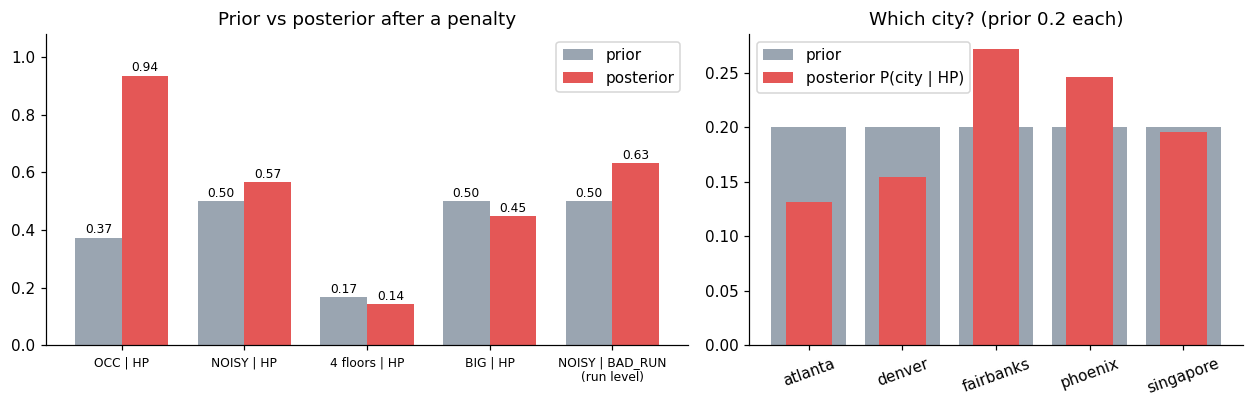

In [41]:
# Chart 6: prior -> posterior after seeing a high-penalty step
pp = pd.DataFrame({"prior": [df.OCC.mean(), df.NOISY.mean(), df.F4.mean(), df.BIG.mean(), runs.NOISY.mean()],
                   "posterior": [post_occ, post_noisy, post_f4, post_big, post_run]},
                  index=["OCC | HP", "NOISY | HP", "4 floors | HP", "BIG | HP", "NOISY | BAD_RUN\n(run level)"])
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
xs = np.arange(len(pp)); wd = 0.38
ax[0].bar(xs - wd / 2, pp.prior, wd, color="#9AA5B1", label="prior")
ax[0].bar(xs + wd / 2, pp.posterior, wd, color="#E45756", label="posterior")
for i, (a, b) in enumerate(zip(pp.prior, pp.posterior)):
    ax[0].text(i - wd / 2, a + .015, f"{a:.2f}", ha="center", fontsize=8); ax[0].text(i + wd / 2, b + .015, f"{b:.2f}", ha="center", fontsize=8)
ax[0].set_xticks(xs); ax[0].set_xticklabels(pp.index, fontsize=8); ax[0].set_ylim(0, 1.08)
ax[0].set_title("Prior vs posterior after a penalty"); ax[0].legend()
ax[1].bar(city_post.index, city_post["prior P(city)"], color="#9AA5B1", label="prior")
ax[1].bar(city_post.index, city_post["posterior P(city|HP)"], width=0.5, color="#E45756", label="posterior P(city | HP)")
ax[1].set_title("Which city? (prior 0.2 each)"); ax[1].legend(); plt.setp(ax[1].get_xticklabels(), rotation=20)
plt.tight_layout(); plt.show()

**Interpretation.** Seeing a penalty is **strong evidence for "occupied"**: P(OCC | HP) = 0.5029 x 0.3735 / 0.2007 = **0.936**, up from the prior 0.3735 (the same 0.936 as the direct count). It is only **weak evidence for the noisy policy** (0.50 to 0.566), because penalties happen under both controllers. For the city, the posterior simply re-weights the equal prior by each city's penalty rate: Fairbanks 0.272 and Phoenix 0.246 become the most likely places, Atlanta 0.132 the least. A penalty slightly lowers belief in "big building" (0.50 to 0.447) and "4 floors" (0.167 to 0.142), consistent with Application 6. At run level, a below-median run is noisy with probability 0.633 versus the prior 0.5.

In plain words: the prior is what we believe before looking at the reward; the posterior is what we believe after seeing a low one. Bayes only reverses the direction of the conditional; it describes association in this simulated data and does not prove that occupancy or the policy *causes* the penalty.

### 5.8b Hand-over: stored results of Sections 5.5-5.8 for the validation
`res_M3` holds the rule-based results and `res_M3_direct` the direct-count twins, computed live, so Section 6 can place them in the three-way validation table without retyping numbers.

In [42]:
res_M3 = {
    "P(HP | OCC)":            p_hp_occ,
    "P(HP | not OCC)":        p_hp_nocc,
    "P(HP | OCC and COLD)":   p_hp_oc,
    "P(HP | BIG)":            p_hp_big,
    "P(OCC and HP) mult.":    p_and_rule,
    "P(OCC,COLD,HP) chain":   p_chain_rule,
    "P(HP) total prob. city": tp_city,
    "P(HP) total prob. policy": tp_pol,
    "P(HP) total prob. floors": tp_fl,
    "P(OCC | HP) Bayes":      post_occ,
    "P(NOISY | HP) Bayes":    post_noisy,
    "P(F4 | HP) Bayes":       post_f4,
    "P(BIG | HP) Bayes":      post_big,
    "P(NOISY | BAD_RUN) Bayes": post_run,
}
res_M3_direct = {
    "P(HP | OCC)":            df[df.OCC].HP.mean(),
    "P(HP | not OCC)":        df[~df.OCC].HP.mean(),
    "P(HP | OCC and COLD)":   df[df.OCC & df.COLD].HP.mean(),
    "P(HP | BIG)":            df[df.BIG].HP.mean(),
    "P(OCC and HP) mult.":    (df.OCC & df.HP).sum() / len(df),
    "P(OCC,COLD,HP) chain":   (df.OCC & df.COLD & df.HP).sum() / len(df),
    "P(HP) total prob. city": df.HP.sum() / len(df),
    "P(HP) total prob. policy": df.HP.sum() / len(df),
    "P(HP) total prob. floors": df.HP.sum() / len(df),
    "P(OCC | HP) Bayes":      df[df.HP].OCC.mean(),
    "P(NOISY | HP) Bayes":    df[df.HP].NOISY.mean(),
    "P(F4 | HP) Bayes":       df[df.HP].F4.mean(),
    "P(BIG | HP) Bayes":      df[df.HP].BIG.mean(),
    "P(NOISY | BAD_RUN) Bayes": runs[runs.BAD_RUN].NOISY.mean(),
}
chk3 = pd.DataFrame({"rule": res_M3, "direct": res_M3_direct})
chk3["|rule - direct|"] = (chk3.rule - chk3.direct).abs()
assert (chk3["|rule - direct|"] < 1e-12).all()        # same finite population -> exact agreement
chk3.round(6)

,rule,direct,|rule - direct|
P(HP | OCC),0.502944,0.502944,0.0
P(HP | not OCC),0.020506,0.020506,0.0
P(HP | OCC and COLD),0.749894,0.749894,0.0
P(HP | BIG),0.179489,0.179489,0.0
P(OCC and HP) mult.,0.187839,0.187839,0.0
"P(OCC,COLD,HP) chain",0.058300,0.058300,0.0
P(HP) total prob. city,0.200686,0.200686,0.0
P(HP) total prob. policy,0.200686,0.200686,0.0
P(HP) total prob. floors,0.200686,0.200686,0.0
P(OCC | HP) Bayes,0.935984,0.935984,0.0


**Exact agreement.** Rule-based and direct-count routes use the same finite population, so they agree to rounding error (below 1e-12). A difference would signal a bug. Differences in uncertainty (block bootstrap) appear only in the validation of Section 6.4, and the independence checks of conditional events (for example NOISY vs HP given OCC) are in Section 5.9.

## 5.9 Application 10: Independence
*Textbook: Sec. 2-6 (independence)*

**Question.** Which conditions in the simulator are independent of each other, and which are not? In particular: are weather and occupancy independent of the controller policy (which would validate the paired design), and does the policy matter only when people are present?

**Events and assumptions.** OCC, HP, NOISY, COLD, HE (high electricity cost), BIG, F4 and one building event. Same equally likely time steps.

**Rule and why it fits.** A and B are independent when P(A and B) = P(A) P(B), equivalently P(B | A) = P(B). We compare the observed joint probability with the product of the two individual probabilities using the difference P(A and B) - P(A) P(B). A difference of zero matches the independence rule; a positive difference means the events occur together more often than the rule predicts, and a negative difference means they occur together less often. For conditional independence, make the same comparison within a subset, such as occupied steps only.

**Uncertainty.** With n = 241,920, a row-level standard error would be misleadingly small because steps within runs are related over time. We therefore use a **day-block bootstrap band**: resample whole run-days (840 blocks, 2,000 resamples, seed 42) and calculate a 95% band for the difference. A band that contains zero is *consistent with independence*; it does not prove independence. Building-level events (BIG, F4, one building) take only 6 distinct values, so their conclusions describe these six buildings rather than a general population.


In [43]:
import numpy as np
import pandas as pd

rng4 = np.random.default_rng(42)
R_BOOT = 2000

# Day-block ids: one block = one run on one day (60 runs x 14 days = 840 blocks)
blk_codes, blk_names = pd.factorize(df.run_id + "|" + df.day.astype(str))
N_BLK = len(blk_names)

def independence_band(a, b, cond=None, R=R_BOOT):
    """Difference P(A and B) - P(A)P(B), with a 95% day-block bootstrap band."""
    m = np.ones(len(df), dtype=bool) if cond is None else np.asarray(cond)
    a = np.asarray(a) & m
    b = np.asarray(b) & m

    # Per block: n in the condition, n_A, n_B, and n_(A and B)
    cols = [m, a, b, a & b]
    cnt = np.column_stack([
        np.bincount(blk_codes, weights=c.astype(float), minlength=N_BLK)
        for c in cols
    ])

    def independence_difference(t):
        n = t[..., 0]
        p_a = t[..., 1] / n
        p_b = t[..., 2] / n
        p_ab = t[..., 3] / n
        return p_ab - p_a * p_b

    # Resample whole run-day blocks to retain within-day dependence
    idx = rng4.integers(0, N_BLK, (R, N_BLK))
    with np.errstate(divide="ignore", invalid="ignore"):
        boot = independence_difference(cnt[idx].sum(axis=1))
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])

    tot = cnt.sum(axis=0)
    p_a, p_b, p_ab = tot[1] / tot[0], tot[2] / tot[0], tot[3] / tot[0]
    difference = p_ab - p_a * p_b
    return {
        "P(A)P(B)": p_a * p_b,
        "P(A and B)": p_ab,
        "difference": difference,
        "band_lo": lo,
        "band_hi": hi
    }

b0 = sorted(df.building.unique())[0]
B2 = df.building == b0
pairs = [  # (name, A, B, condition)
    ("OCC vs NOISY",                df.OCC,   df.NOISY, None),
    ("COLD vs NOISY",               df.COLD,  df.NOISY, None),
    ("OCC vs HP",                   df.OCC,   df.HP,    None),
    ("NOISY vs HP",                 df.NOISY, df.HP,    None),
    ("OCC vs COLD",                 df.OCC,   df.COLD,  None),
    ("COLD vs HP",                  df.COLD,  df.HP,    None),
    ("OCC vs HE (high elec. cost)", df.OCC,  df.HE,    None),
    (f"{b0} vs OCC",                B2,       df.OCC,   None),
    ("BIG vs NOISY",                df.BIG,   df.NOISY, None),
    ("BIG vs OCC",                  df.BIG,   df.OCC,   None),
    ("BIG vs HP",                   df.BIG,   df.HP,    None),
    ("F4 vs HP",                    df.F4,    df.HP,    None),
    ("NOISY vs HP | OCC",           df.NOISY, df.HP,    df.OCC),
    ("NOISY vs HP | not OCC",       df.NOISY, df.HP,    ~df.OCC),
]

rows = []
for name, a, b, cond in pairs:
    r = independence_band(a, b, cond)
    r["pair"] = name
    r["verdict"] = (
        "consistent with independence"
        if r["band_lo"] <= 0 <= r["band_hi"]
        else ("positive dependence" if r["difference"] > 0 else "negative dependence")
    )
    rows.append(r)

ind = pd.DataFrame(rows).set_index("pair")[
    ["P(A)P(B)", "P(A and B)", "difference", "band_lo", "band_hi", "verdict"]
]
ind.round(4)


,P(A)P(B),P(A and B),difference,band_lo,band_hi,verdict
pair,,,,,,
OCC vs NOISY,0.1867,0.1867,0.0000,-0.0078,0.0086,consistent with independence
COLD vs NOISY,0.1416,0.1416,0.0000,-0.0123,0.0133,consistent with independence
OCC vs HP,0.0750,0.1878,0.1129,0.1058,0.1202,positive dependence
NOISY vs HP,0.1003,0.1136,0.0133,0.0057,0.0212,positive dependence
OCC vs COLD,0.1058,0.0777,-0.0280,-0.0347,-0.0210,negative dependence
COLD vs HP,0.0568,0.0689,0.0121,0.0050,0.0186,positive dependence
OCC vs HE (high elec. cost),0.0934,0.1891,0.0957,0.0882,0.1033,positive dependence
building_train_1 vs OCC,0.0622,0.0631,0.0008,-0.0056,0.0069,consistent with independence
BIG vs NOISY,0.2500,0.2500,0.0000,-0.0164,0.0173,consistent with independence


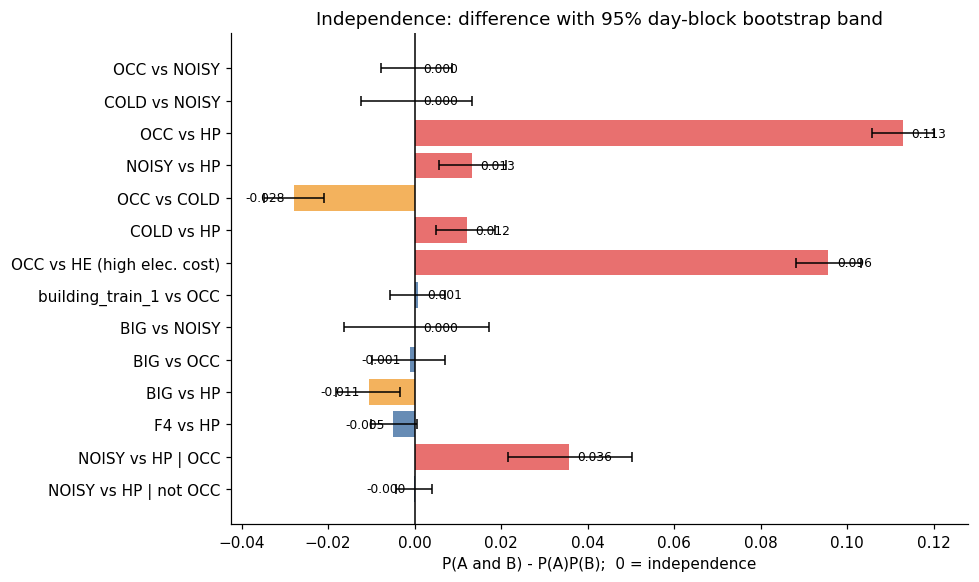

In [44]:
# Chart 7: independence comparison per pair; zero is the independence reference
d = ind.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.4))
col = d.verdict.map({
    "consistent with independence": "#4C78A8",
    "positive dependence": "#E45756",
    "negative dependence": "#F2A541"
})
ax.barh(d.index, d.difference, color=col, alpha=.85)
ax.errorbar(
    d.difference, range(len(d)),
    xerr=[d.difference - d.band_lo, d.band_hi - d.difference],
    fmt="none", ecolor="black", capsize=3, lw=1
)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("P(A and B) - P(A)P(B);  0 = independence")
ax.set_title("Independence: difference with 95% day-block bootstrap band")
for i, (value, verdict) in enumerate(zip(d.difference, d.verdict)):
    offset = .002 if value >= 0 else -.002
    ax.text(value + offset, i, f"{value:.3f}", va="center", ha="left" if value >= 0 else "right", fontsize=8)
plt.tight_layout()
plt.show()


**Interpretation.**
- *By design.* For OCC vs NOISY, COLD vs NOISY and BIG vs NOISY, P(A and B) equals P(A)P(B): each building/weather pairing has both policies, and the paired policies share timestamps, occupancy and outside temperature (checked in 2.4). This supports the paired simulation design: the two policies were compared under matching conditions.
- *Positive dependence.* For OCC vs HP, the observed joint probability (about 0.188) is above the independence product (about 0.075). High electricity cost is also more common with OCC than its independence product predicts. NOISY vs HP and COLD vs HP show smaller positive differences.
- *Negative dependence.* For OCC vs COLD, P(A and B) is below P(A)P(B), because occupied hours are mostly daytime while cold outside air is mostly at night.
- *Conditional independence.* For NOISY vs HP given OCC, the observed joint probability is above its product. Given an empty building, the difference is near zero and its day-block band contains zero: these data are consistent with policy and HP being independent during unoccupied steps. This is conditional independence in action: the overall relationship can differ from the relationship inside a subgroup.
- *Building-level pairs.* BIG vs OCC, BIG vs HP, F4 vs HP and one building vs OCC use only 6 distinct buildings (and one 4-floor building). Treat them as descriptions of these buildings, not general laws. A small difference can be consistent with independence when its block-bootstrap band contains zero.


In [45]:
# hand-over of independence results for the slides / insights
res_M4_ind = ind[["difference", "band_lo", "band_hi", "verdict"]].copy()
print(res_M4_ind.verdict.value_counts().to_dict())


{'consistent with independence': 7, 'positive dependence': 5, 'negative dependence': 2}


### 5.9b Mutually exclusive is not independent, and mutual independence of three events
*Textbook: Sec. 2-6 (independence), Sec. 2-3 (mutually exclusive events)*

**Question.** (a) COLD and HOT never happen together; does that make them independent? (b) For three events, is checking each pair enough to call all three events mutually independent?

**Rules and why they fit.**
- *Mutually exclusive versus independent.* Mutually exclusive events with positive probabilities are dependent. If A happens, B cannot, so P(B | A) = 0 while P(B) > 0. Independence requires P(A and B) = P(A)P(B). For COLD and HOT, the joint probability is 0 but the product of their probabilities is greater than 0, so they are not independent.
- *Mutual independence of three events.* A, B and C are mutually independent only when the independence rule holds for all three pairs **and** for all three together: P(A and B) = P(A)P(B), P(A and C) = P(A)P(C), P(B and C) = P(B)P(C), and P(A and B and C) = P(A)P(B)P(C). The table below compares each joint probability with the corresponding product. Application 10 separately uses day-block bootstrap bands when judging pairwise results.

In [46]:
# (a) Mutually exclusive events with positive probability are dependent
p_cold9 = df.COLD.mean()
p_hot9 = df.HOT.mean()
p_both9 = (df.COLD & df.HOT).mean()
product_cold_hot9 = p_cold9 * p_hot9
diff_cold_hot9 = p_both9 - product_cold_hot9

print(
    f"P(COLD) = {p_cold9:.4f}  P(HOT) = {p_hot9:.4f}  "
    f"P(COLD and HOT) = {p_both9:.4f}  "
    f"vs  P(COLD)P(HOT) = {product_cold_hot9:.4f}"
)
print(
    f"P(HOT | COLD) = {(df.HOT & df.COLD).sum() / df.COLD.sum():.4f}  "
    f"vs  P(HOT) = {p_hot9:.4f}  "
    f"-> difference P(COLD and HOT) - P(COLD)P(HOT) = {diff_cold_hot9:.4f}; dependent"
)
assert p_both9 == 0 and product_cold_hot9 > 0


# (b) Mutual independence of three events:
# all three pairwise rules AND the three-event rule must hold
def mutual_check(a, b, c, names):
    pa, pb, pc = a.mean(), b.mean(), c.mean()
    pab = (a & b).mean()
    pac = (a & c).mean()
    pbc = (b & c).mean()
    pabc = (a & b & c).mean()

    rows = {
        f"{names[0]} , {names[1]}": (pab, pa * pb),
        f"{names[0]} , {names[2]}": (pac, pa * pc),
        f"{names[1]} , {names[2]}": (pbc, pb * pc),
        "all three": (pabc, pa * pb * pc),
    }

    t = pd.DataFrame(rows, index=["P(joint)", "product of P"]).T
    t["difference"] = t["P(joint)"] - t["product of P"]
    t["product rule holds"] = np.isclose(t["difference"], 0.0)
    return t


mi_1 = mutual_check(df.OCC, df.COLD, df.NOISY, ["OCC", "COLD", "NOISY"])
mi_2 = mutual_check(df.OCC, df.COLD, df.HP, ["OCC", "COLD", "HP"])

print(
    "Triple 1: OCC, COLD, NOISY -> mutually independent:",
    bool(mi_1["product rule holds"].all())
)
display(mi_1.round(4))

print(
    "Triple 2: OCC, COLD, HP -> mutually independent:",
    bool(mi_2["product rule holds"].all())
)
display(mi_2.round(4))


# The policy is independent of the joint event (OCC and COLD) if:
# P(OCC and COLD and NOISY) = P(OCC and COLD)P(NOISY)
occ_cold9 = df.OCC & df.COLD
p_joint_policy9 = (occ_cold9 & df.NOISY).mean()
p_product_policy9 = occ_cold9.mean() * df.NOISY.mean()
diff_policy9 = p_joint_policy9 - p_product_policy9

print(
    f"\nP(OCC and COLD and NOISY) = {p_joint_policy9:.4f} | "
    f"P(OCC and COLD)P(NOISY) = {p_product_policy9:.4f} | "
    f"difference = {diff_policy9:.4f}"
)
assert np.isclose(diff_policy9, 0.0)

P(COLD) = 0.2832  P(HOT) = 0.3861  P(COLD and HOT) = 0.0000  vs  P(COLD)P(HOT) = 0.1093
P(HOT | COLD) = 0.0000  vs  P(HOT) = 0.3861  -> difference P(COLD and HOT) - P(COLD)P(HOT) = -0.1093; dependent
Triple 1: OCC, COLD, NOISY -> mutually independent: False


,P(joint),product of P,difference,product rule holds
"OCC , COLD",0.0777,0.1058,-0.028,False
"OCC , NOISY",0.1867,0.1867,0.000,True
"COLD , NOISY",0.1416,0.1416,0.000,True
all three,0.0389,0.0529,-0.014,False


Triple 2: OCC, COLD, HP -> mutually independent: False


,P(joint),product of P,difference,product rule holds
"OCC , COLD",0.0777,0.1058,-0.0280,False
"OCC , HP",0.1878,0.0750,0.1129,False
"COLD , HP",0.0689,0.0568,0.0121,False
all three,0.0583,0.0212,0.0371,False



P(OCC and COLD and NOISY) = 0.0389 | P(OCC and COLD)P(NOISY) = 0.0389 | difference = 0.0000


**Interpretation.** (a) COLD and HOT are mutually exclusive: they never happen together, so P(COLD and HOT) = 0. But P(COLD)P(HOT) is about 0.1093, not 0. Because the joint probability does not equal the product, COLD and HOT are dependent. Equivalently, P(HOT | COLD) = 0 while P(HOT) = 0.386: knowing the step is cold tells us it is not hot.

(b) In Triple 1, NOISY is independent of OCC and of COLD individually, and it is also independent of the combined event OCC and COLD. However, OCC and COLD are dependent: P(OCC and COLD) = 0.0777, while P(OCC)P(COLD) = 0.1058. So the three events are **not** mutually independent. In particular, P(OCC and COLD and NOISY) equals P(OCC and COLD)P(NOISY), but it does not equal P(OCC)P(COLD)P(NOISY).

Triple 2 fails because OCC, COLD and HP are dependent in each pair, and the three-event product rule also fails. Mutual independence requires the independence rule to hold for **all three pairs and the three-event combination**. Checking only some pairs is not enough.

# 6. Validation
*Rule-based vs direct vs independent re-implementation, block bootstrap, preprocessing sensitivity.*

**Purpose.** Prove the main results are correct by computing each one in **independent ways, all with plain Python functions** (no random simulation):
1. **Route 1 - probability rule** (formula from Chapter 2, using the stored hand-over results of Members 2 and 3).
2. **Route 2 - direct calculation** (a Boolean filter on the observations: count of favourable steps / count of possible steps).
3. **Route 3 - independent re-implementation** (a plain Python loop over the observations and a cross-tabulation, which share no code with route 2).

Because all routes use the same finite population of 241,920 steps, they must agree to rounding error. Any gap is a bug, so the cell stops (`assert`) if they do not.

### 6.1 Three-way validation table

In [47]:
def loop_count(event, given=None):
    '''Route 3a: plain Python loop. P(event | given), or P(event) when given is None.'''
    ev = event.to_numpy().tolist(); gv = None if given is None else given.to_numpy().tolist()
    num = den = 0
    for k in range(len(ev)):
        if gv is None or gv[k]:
            den += 1
            if ev[k]: num += 1
    return num / den

def crosstab_cond(event, given):
    '''Route 3b: P(event | given) read from a cross-tabulation (rows = given, columns = event).'''
    t = pd.crosstab(given, event)
    return t.loc[True, True] / t.loc[True].sum()

OC = df.OCC & df.COLD
rows = [
    # name,                 route 1 (rule),                    route 2 (direct filter),  route 3 (independent)
    ("P(HP)",               tp_city,                           df.HP.mean(),             loop_count(df.HP)),
    ("P(HP | OCC)",         (df.OCC & df.HP).mean() / df.OCC.mean(), Pc(df.HP, df.OCC), crosstab_cond(df.HP, df.OCC)),
    ("P(HP | not OCC)",     res_M3["P(HP | not OCC)"],         Pc(df.HP, ~df.OCC),       crosstab_cond(df.HP, ~df.OCC)),
    ("P(HP | OCC and COLD)", res_M3["P(HP | OCC and COLD)"],   Pc(df.HP, OC),            loop_count(df.HP, OC)),
    ("P(OCC | HP)",         post_occ,                          Pc(df.OCC, df.HP),        crosstab_cond(df.OCC, df.HP)),
    ("P(NOISY | HP)",       post_noisy,                        Pc(df.NOISY, df.HP),      crosstab_cond(df.NOISY, df.HP)),
    ("P(OCC and HP)",       res_M3["P(OCC and HP) mult."],     (df.OCC & df.HP).mean(),  loop_count(df.OCC & df.HP)),
    ("P(OCC or HP)",        res_M2["P(OCC or HP) addition"],   (df.OCC | df.HP).mean(), loop_count(df.OCC | df.HP)),
    ("P(OCC,COLD,HP) chain", res_M3["P(OCC,COLD,HP) chain"],   (OC & df.HP).mean(),      loop_count(OC & df.HP)),
]
val = pd.DataFrame(rows, columns=["event", "rule", "direct", "independent", ]).set_index("event")
val["|rule-direct|"] = (val.rule - val.direct).abs()
val["|direct-independent|"] = (val.direct - val.independent).abs()
assert (val[["|rule-direct|", "|direct-independent|"]].max(axis=1) < 1e-12).all()
val.round(6)

,rule,direct,independent,|rule-direct|,|direct-independent|
event,,,,,
P(HP),0.200686,0.200686,0.200686,0.0,0.0
P(HP | OCC),0.502944,0.502944,0.502944,0.0,0.0
P(HP | not OCC),0.020506,0.020506,0.020506,0.0,0.0
P(HP | OCC and COLD),0.749894,0.749894,0.749894,0.0,0.0
P(OCC | HP),0.935984,0.935984,0.935984,0.0,0.0
P(NOISY | HP),0.566056,0.566056,0.566056,0.0,0.0
P(OCC and HP),0.187839,0.187839,0.187839,0.0,0.0
P(OCC or HP),0.386326,0.386326,0.386326,0.0,0.0
"P(OCC,COLD,HP) chain",0.058300,0.058300,0.058300,0.0,0.0


**Reading the table.** All three columns are equal to rounding error (both difference columns are below 1e-12, and the assertion above stops the notebook otherwise). The rule route (multiplication, addition, total probability, Bayes) and the direct count are different calculations that must give the same number on a finite population; the loop and cross-tabulation confirm the direct count with different code. If a rule and a count disagreed, we would suspect a wrongly defined event or a mistake in a formula. What this agreement shows: on a finite population the rule route and the direct count are algebraically the same quantity, so agreement confirms that the events and formulas are coded correctly. It does not show that the numbers would carry over to new buildings or weather; that question is addressed by the block bootstrap (6.4) and the sensitivity checks (6.5).

### 6.2 Validation of the stored run-level columns
The file stores run summaries that can be recomputed from the steps. This is a second independent route that needs no simulation: if the stored `run_*` values equal our recomputation, we have also confirmed that the 60-row `runs` table is trustworthy.

In [48]:
g = df_raw.groupby("run_id")
pairs_chk = {"run_mean_reward":     g.reward.mean(),
             "run_avg_occupancy":   g.occupancy.mean(),
             "run_avg_zone_temp_K": g.zone_temp_mean_K.mean(),
             "run_total_reward":    g.reward.sum()}
chk = pd.DataFrame({c: v - g[c].first() for c, v in pairs_chk.items() if c in df_raw.columns})
print("stored run columns checked:", list(chk.columns))
chk_max = chk.abs().max()
print("largest absolute difference over the 60 runs:"); print(chk_max.to_string())
assert len(chk.columns) > 0 and (chk_max < 1e-3).all()          # agreement up to the rounding of the stored values

stored run columns checked: ['run_mean_reward', 'run_avg_occupancy', 'run_avg_zone_temp_K', 'run_total_reward']
largest absolute difference over the 60 runs:
run_mean_reward        1.062180e-08
run_avg_occupancy      7.105427e-15
run_avg_zone_temp_K    6.599547e-05
run_total_reward       4.282709e-05


### 6.3 Counting validation (exact enumeration)
Application 3 used C(30,3)/C(60,3) = 0.1186 for the chance that 3 runs chosen without replacement are all noisy. Independent route: list **every** 3-run subset with `itertools.combinations` and count how many are all noisy. The same enumeration with `permutations` gives 60P3, and drawing with replacement gives 0.5^3 = 0.125 - a *modeling* difference (sampling with vs without replacement), not an error.

In [49]:
from itertools import combinations, permutations
from math import comb, perm

noisy_flag = runs.NOISY.to_numpy().tolist()
subsets = list(combinations(range(len(noisy_flag)), 3))          # all C(60,3) subsets
all_noisy = sum(1 for s in subsets if all(noisy_flag[k] for k in s))
print(f"subsets listed: {len(subsets)}  (C(60,3) = {comb(60, 3)})")
print(f"all-noisy subsets: {all_noisy}  (C(30,3) = {comb(30, 3)})")
print(f"enumeration = {all_noisy / len(subsets):.4f}   formula C(30,3)/C(60,3) = {comb(30, 3) / comb(60, 3):.4f}")
print(f"ordered draws: 60P3 = {perm(60, 3)} = {len(list(permutations(range(60), 3)))} listed;  with replacement 0.5^3 = {0.5**3:.4f}")
assert len(subsets) == comb(60, 3) and all_noisy == comb(30, 3)

subsets listed: 34220  (C(60,3) = 34220)
all-noisy subsets: 4060  (C(30,3) = 4060)
enumeration = 0.1186   formula C(30,3)/C(60,3) = 0.1186
ordered draws: 60P3 = 205320 = 205320 listed;  with replacement 0.5^3 = 0.1250


### 6.4 The honest uncertainty: block bootstrap for P(HP | OCC)
A row-level interval treats 241,920 steps as independent, which they are not. We resample **whole units** instead: run-days (blocks of consecutive steps) and entire runs. The point estimate is the same; only the uncertainty changes. Intervals are 95% percentile intervals with 2,000 resamples (seed 42).

In [50]:
rng6 = np.random.default_rng(42)
occ = df[df.OCC]
n_occ, p_hat = len(occ), occ.HP.mean()
R = 2000

# (1) naive row-level: equivalent to resampling occupied rows independently (binomial draw)
naive = rng6.binomial(n_occ, p_hat, R) / n_occ

# (2) day-block: resample run-days that have occupied steps
gd = occ.groupby(["run_id", "day"]).HP.agg(["size", "sum"]).to_numpy()
ix = rng6.integers(0, len(gd), (R, len(gd)))
dayb = gd[ix, 1].sum(1) / gd[ix, 0].sum(1)

# (3) run-block: resample the 60 runs
gr = occ.groupby("run_id").HP.agg(["size", "sum"]).to_numpy()
ix = rng6.integers(0, len(gr), (R, len(gr)))
runb = gr[ix, 1].sum(1) / gr[ix, 0].sum(1)

ci = pd.DataFrame({"resampling unit": ["occupied rows (naive)", f"run-days ({len(gd)} blocks)", f"runs ({len(gr)} blocks)"],
                   "lower": [np.percentile(x, 2.5) for x in (naive, dayb, runb)],
                   "upper": [np.percentile(x, 97.5) for x in (naive, dayb, runb)]})
ci["width"] = ci.upper - ci.lower
print(f"point estimate P(HP | OCC) = {p_hat:.4f}")
ci.round(4)

point estimate P(HP | OCC) = 0.5029


,resampling unit,lower,upper,width
0,occupied rows (naive),0.4995,0.5062,0.0066
1,run-days (702 blocks),0.4718,0.5331,0.0612
2,runs (60 blocks),0.4256,0.5787,0.1531


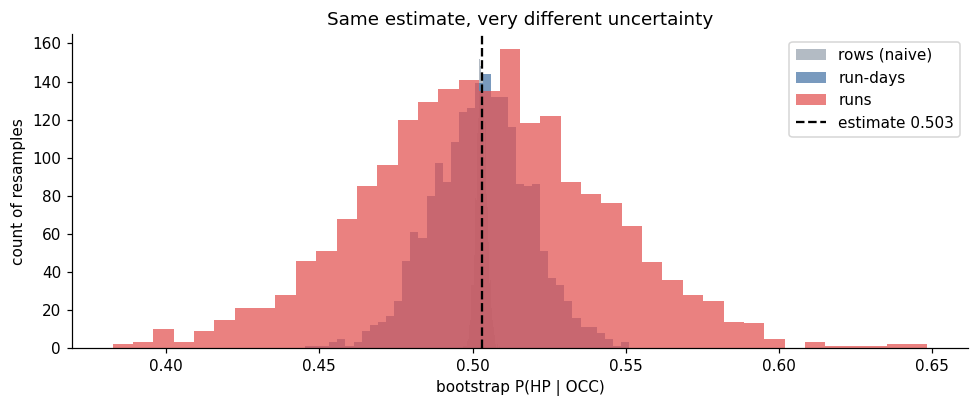

In [51]:
# Chart 8: the naive interval is far too narrow
fig, ax = plt.subplots(figsize=(9, 3.8))
for x, c, l in [(naive, "#9AA5B1", "rows (naive)"), (dayb, "#4C78A8", "run-days"), (runb, "#E45756", "runs")]:
    ax.hist(x, bins=40, alpha=.75, color=c, label=l)
ax.axvline(p_hat, color="black", ls="--", label=f"estimate {p_hat:.3f}")
ax.set_xlabel("bootstrap P(HP | OCC)"); ax.set_ylabel("count of resamples")
ax.set_title("Same estimate, very different uncertainty"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.** The estimate P(HP | OCC) = 0.503 does not change, but its uncertainty does: the naive row-level interval is only about +/-0.003 wide, the day-block interval is roughly [0.47, 0.53] and the run-block interval roughly [0.43, 0.58]. The true uncertainty comes from having only 60 runs (and 840 run-days), not 241,920 rows. This is why independence was judged with a block band and why later tasks should use run-level or day-level summaries.

### 6.5 Preprocessing sensitivity
How much do the probabilities move if we drop the worst 1% of rewards (`df_trim`), remove Fairbanks (`df_no_fb`), or keep only the clean policy (`df_pid`)? Event definitions and thresholds stay fixed; each probability is recomputed as count / rows of that frame.

In [52]:
def stats(d):
    return {"rows": len(d), "P(OCC)": d.OCC.mean(), "P(HP)": d.HP.mean(),
            "P(HP | OCC)": Pc(d.HP, d.OCC) if d.OCC.any() else np.nan,
            "P(OCC | HP)": Pc(d.OCC, d.HP) if d.HP.any() else np.nan}
sens_tab = pd.DataFrame({"full data": stats(df), "trim worst 1% reward": stats(df_trim),
                         "no Fairbanks": stats(df_no_fb), "pid_water only": stats(df_pid)}).T
display(sens_tab.round(4))

# leave-one-building-out and BIG vs not BIG
loo = pd.Series({b: Pc(df[df.building != b].HP, df[df.building != b].OCC) for b in sorted(df.building.unique())},
                name="P(HP | OCC) without this building")
print("leave-one-building-out:"); display(loo.round(4).to_frame())
print(f"range over the 6 values: {loo.min():.3f} to {loo.max():.3f}")
print(f"P(HP | OCC, BIG) = {Pc(df.HP, df.OCC & df.BIG):.3f}  vs  P(HP | OCC, not BIG) = {Pc(df.HP, df.OCC & ~df.BIG):.3f}")

,rows,P(OCC),P(HP),P(HP | OCC),P(OCC | HP)
full data,241920.0,0.3735,0.2007,0.5029,0.9360
trim worst 1% reward,239500.0,0.3672,0.1926,0.4893,0.9328
no Fairbanks,193536.0,0.3751,0.1827,0.4790,0.9835
pid_water only,120960.0,0.3735,0.1742,0.4316,0.9255


leave-one-building-out:


,P(HP | OCC) without this building
building_train_1,0.4955
building_train_2,0.4949
building_train_4,0.5169
building_train_5,0.5151
building_train_7,0.4900
building_train_8,0.5054


range over the 6 values: 0.490 to 0.517
P(HP | OCC, BIG) = 0.473  vs  P(HP | OCC, not BIG) = 0.533


In [53]:
# threshold sensitivity: HP is defined as reward < t, an analyst choice
th_rows = []
for t in (-0.05, -0.1, -0.2):
    hp = df.reward < t
    th_rows.append({"threshold": t, "P(HP)": hp.mean(), "P(HP | OCC)": Pc(hp, df.OCC),
                    "P(HP | not OCC)": Pc(hp, ~df.OCC),
                    "fairbanks > atlanta": hp.groupby(df.city).mean()["fairbanks"] > hp.groupby(df.city).mean()["atlanta"],
                    "noisy > clean": Pc(hp, df.NOISY) > Pc(hp, ~df.NOISY)})
th_tab = pd.DataFrame(th_rows).set_index("threshold")
display(th_tab.round(4))

# does the ORDERING of the main findings survive every preprocessing choice?
def order_checks(d):
    hp_c = d.HP.groupby(d.city).mean()
    out = {"occupied > empty": Pc(d.HP, d.OCC) > Pc(d.HP, ~d.OCC)}
    out["Fairbanks > Atlanta"] = hp_c["fairbanks"] > hp_c["atlanta"] if {"fairbanks", "atlanta"} <= set(hp_c.index) else np.nan
    out["Phoenix > Atlanta"]   = hp_c["phoenix"]   > hp_c["atlanta"] if {"phoenix", "atlanta"} <= set(hp_c.index) else np.nan
    out["noisy > clean"]       = Pc(d.HP, d.NOISY) > Pc(d.HP, ~d.NOISY) if d.NOISY.any() and (~d.NOISY).any() else np.nan
    return out
robust = pd.DataFrame({"full": order_checks(df), "trim": order_checks(df_trim),
                       "no Fairbanks": order_checks(df_no_fb), "pid only": order_checks(df_pid)})
display(robust)

,P(HP),P(HP | OCC),P(HP | not OCC),fairbanks > atlanta,noisy > clean
threshold,,,,,
-0.05,0.3415,0.8512,0.0377,True,True
-0.10,0.2007,0.5029,0.0205,True,True
-0.20,0.0837,0.2121,0.0072,True,True


,full,trim,no Fairbanks,pid only
occupied > empty,True,True,True,True
Fairbanks > Atlanta,True,True,NaN,True
Phoenix > Atlanta,True,True,True,True
noisy > clean,True,True,True,NaN


**Interpretation.** The *level* of each probability moves with the preprocessing and with the threshold: P(HP) falls from 0.2007 to about 0.193 (trim), 0.183 (no Fairbanks) and 0.174 (clean policy only), and P(HP | OCC) from 0.503 to about 0.49, 0.48 and 0.43. A stricter threshold (-0.2) shrinks P(HP) to about 0.08 and a looser one (-0.05) raises it to about 0.34, so every number is conditional on our threshold choice. Dropping one building at a time moves P(HP | OCC) within a narrow range, so no single building drives the result. The *ordering* of the findings is robust: occupied >> empty, Fairbanks and Phoenix > Atlanta, noisy > clean (cells marked NaN are not testable because the removed group is part of the comparison). Conclusion: our qualitative findings are stable; the exact levels are specific to this threshold, these 60 runs and these two baseline policies.

### 6.6 Summary of the validation
| Kind of difference | Where | Size | Why |
|---|---|---|---|
| Exact agreement | rule vs direct vs loop/crosstab (6.1), run columns (6.2), enumeration (6.3), 5.4c, 5.8b | below 1e-12 (run columns about 1e-4 from stored rounding) | same finite population |
| Modeling | with vs without replacement (6.3); rows vs blocks (6.4) | 0.1186 vs 0.125; +/-0.003 (rows) vs +/-0.03 (run-days) and +/-0.08 (runs) | steps are autocorrelated, runs are a finite population |


# 7. Insights, limitations and competition relevance
*Final charts, six findings, assumptions and limitations, use in the competition.*

Every number below is computed in the next cells from the live variables of Sections 4-6 (nothing is typed in by hand), so the text always matches the output.

## 7.1 Final charts
Already drawn earlier: temperature regime and city shares (Chart 1), the (building, weather) grid (2), run-level spread and the p_run histogram (3), conditional probabilities (4), the probability tree (5.6), city and building rates (5), prior -> posterior (6), the independence comparison per pair (7), bootstrap histogram (8). Six more complete the set. One palette throughout: blue = clean policy / reference, red = noisy policy / high penalty.


**Chart 9 reading.** Most steps sit near zero, with a long tail of heavy penalties. The red line is our analyst threshold; Section 6.5 shows how the probabilities move for -0.05 and -0.2.

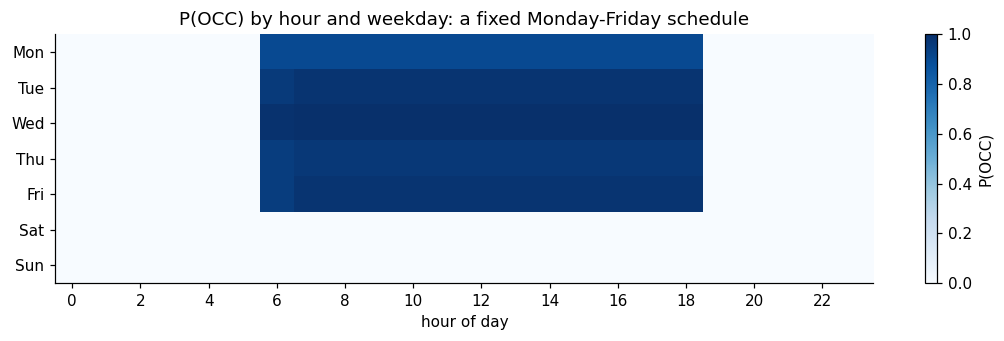

In [54]:
# Chart 10 (d): when is the building occupied? P(OCC) by hour x weekday
hm = df.groupby(["dow", "hour"]).OCC.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(hm.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xlabel("hour of day"); ax.set_title("P(OCC) by hour and weekday: a fixed Monday-Friday schedule")
plt.colorbar(im, ax=ax, label="P(OCC)"); plt.tight_layout(); plt.show()

**Chart 10 reading.** Occupancy follows a fixed weekday working-hours pattern and is empty on weekends. That is why P(OCC) is only 0.37 (about one step in three) and why conditioning on OCC changes everything: the model has a built-in schedule, not random arrivals.

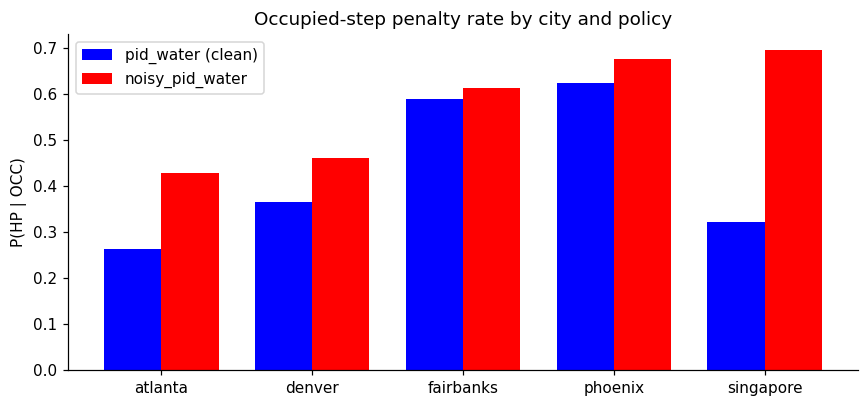

policy,noisy_pid_water,pid_water
city,,
atlanta,0.4282,0.2635
denver,0.4608,0.3663
fairbanks,0.6132,0.5882
phoenix,0.6771,0.6230
singapore,0.6952,0.3228


In [56]:
# Chart 11 (i): P(HP | OCC) by city and policy
t = df[df.OCC].groupby(["city", "policy"]).HP.mean().unstack()
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(len(t)); w = .38
ax.bar(x - w/2, t["pid_water"], w, color="BLUE", label="pid_water (clean)")
ax.bar(x + w/2, t["noisy_pid_water"], w, color="RED", label="noisy_pid_water")
ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_ylabel("P(HP | OCC)")
ax.set_title("Occupied-step penalty rate by city and policy"); ax.legend()
plt.tight_layout(); plt.show()
display(t.round(4))

**Chart 11 reading.** The red bar is above the blue bar in every city, so the noisy-policy effect is not an artefact of one climate; the city sets the level and the policy shifts it.

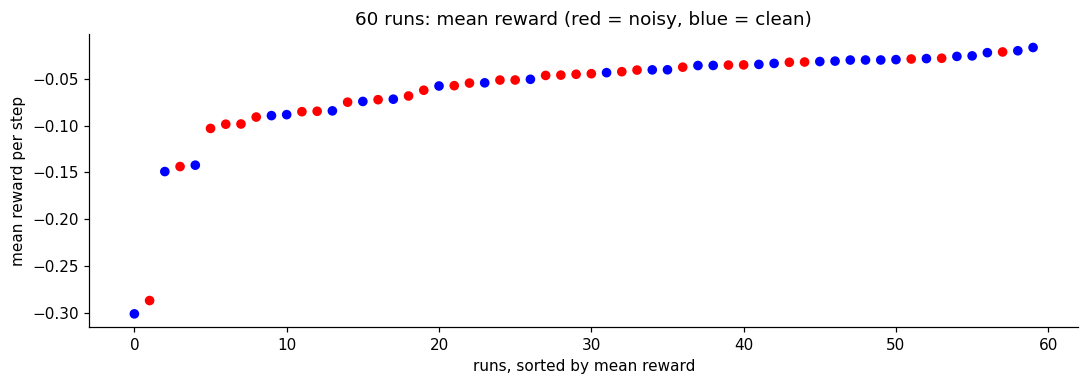

In [58]:
# Chart 12 (j): run_mean_reward for each of the 60 runs, coloured by policy
rr = df.groupby(["run_id", "policy"]).reward.mean().reset_index().sort_values("reward").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.scatter(rr.index, rr.reward, c=np.where(rr.policy == "noisy_pid_water","RED" , "BLUE"), s=28)
ax.set_xlabel("runs, sorted by mean reward"); ax.set_ylabel("mean reward per step")
ax.set_title("60 runs: mean reward (red = noisy, blue = clean)")
plt.tight_layout(); plt.show()

**Chart 12 reading.** The 60 run-level scores are the real sample, not 241,920 rows. Red dots concentrate at the low end, but the two colours overlap: building and weather also matter.

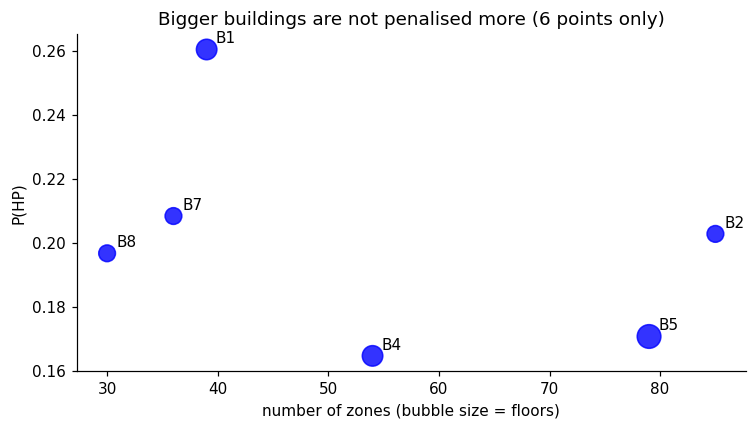

,zones,floors,p_hp,p_hp_occ
building,,,,
building_train_1,39,3,0.2604,0.5395
building_train_2,85,2,0.2029,0.5446
building_train_4,54,3,0.1648,0.4341
building_train_5,79,4,0.1708,0.4420
building_train_7,36,2,0.2084,0.5700
building_train_8,30,2,0.1968,0.4909


In [60]:
# Chart 13 (k): building size vs P(HP) for the 6 buildings
bt = df.groupby("building").agg(zones=("run_n_zones", "first"), floors=("run_n_floors", "first"), p_hp=("HP", "mean"))
bt["p_hp_occ"] = df[df.OCC].groupby("building").HP.mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(bt.zones, bt.p_hp, s=60 * bt.floors, color="BLUE", alpha=.8)
for b, r in bt.iterrows(): ax.annotate(b.replace("building_train_", "B"), (r.zones, r.p_hp), xytext=(6, 4), textcoords="offset points")
ax.set_xlabel("number of zones (bubble size = floors)"); ax.set_ylabel("P(HP)")
ax.set_title("Bigger buildings are not penalised more (6 points only)")
plt.tight_layout(); plt.show(); display(bt.round(4))

**Chart 13 reading.** There is no upward trend of penalty rate with size. With only six distinct buildings this is a description of these six designs, not a law.

## 7.2 The six findings (live numbers)

In [61]:
# ---- pull every number from live variables
p_all, p_o, p_n = df.HP.mean(), Pc(df.HP, df.OCC), Pc(df.HP, ~df.OCC)
share_occ = Pc(df.OCC, df.HP)
pc = df.groupby("city").HP.mean()
p_o_clean = Pc(df.HP, df.OCC & ~df.NOISY); p_o_noisy = Pc(df.HP, df.OCC & df.NOISY)

pr = df.groupby(["building", "weather", "policy"]).agg(r=("reward", "mean")).r.unstack()
worse_reward = int((pr["noisy_pid_water"] < pr["pid_water"]).sum()); n_pairs = len(pr)
ph = df[df.OCC].groupby(["building", "weather", "policy"]).HP.mean().unstack()
worse_hp = int((ph["noisy_pid_water"] > ph["pid_water"]).sum())

empty_policy = ind.loc["NOISY vs HP | not OCC"]
paired_policy = ind.loc["OCC vs NOISY"]
run_hpo = df[df.OCC].groupby("run_id").HP.mean()
p_big, p_nbig = Pc(df.HP, df.BIG), Pc(df.HP, ~df.BIG); p_f4 = Pc(df.HP, df.F4)
w_day, w_run = ci.set_index("resampling unit").width.iloc[0] / 2, ci.set_index("resampling unit").width.iloc[2] / 2

F = [
 ("1. Penalties are an occupied-building phenomenon",
  f"P(HP | OCC) = {p_o:.3f} vs P(HP | not OCC) = {p_n:.3f}; {share_occ:.1%} of penalised steps happen while occupied.",
  "Occupancy is the main driver; evaluating a controller on empty hours says little."),
 ("2. The noisy policy raises the occupied-step penalty rate",
  f"P(HP | OCC) goes from {p_o_clean:.3f} (clean) to {p_o_noisy:.3f} (noisy); noisy is worse in {worse_hp} of {n_pairs} paired runs "
  f"({worse_reward} of {n_pairs} by mean reward); for empty steps, the independence difference is {empty_policy.difference:.4f} "
  f"(95% band {empty_policy.band_lo:.4f} to {empty_policy.band_hi:.4f}).",
  "The controller's relationship with the penalty changes by occupancy; among empty steps, the result is consistent with independence."),
 ("3. Extreme climates are harder",
  f"P(HP) = {pc.max():.3f} in {pc.idxmax()} and {pc.nlargest(2).iloc[1]:.3f} in {pc.nlargest(2).index[1]} vs {pc.min():.3f} in {pc.idxmin()}.",
  "Weather sets the difficulty level; a curriculum can go from mild to extreme cities."),
 ("4. Weather and occupancy are independent of policy",
  f"For OCC and NOISY, P(A and B) - P(A)P(B) = {paired_policy.difference:.4f} "
  f"(95% band {paired_policy.band_lo:.4f} to {paired_policy.band_hi:.4f}).",
  "The paired design is fair: policy differences come from the controller, not from different conditions."),
 ("5. Pooled probabilities hide large run-to-run spread",
  f"Run-level P(HP | OCC) ranges from {run_hpo.min():.3f} to {run_hpo.max():.3f}; the bootstrap half-width grows from "
  f"{(ci.upper[0]-ci.lower[0])/2:.3f} (rows) to {w_day:.3f} (run-days) and {w_run:.3f} (runs).",
  "The honest sample size is 60 runs / 840 run-days, not 241,920 rows."),
 ("6. Building size and floors do not raise penalties",
  f"P(HP | BIG) = {p_big:.3f} vs {p_nbig:.3f} for smaller buildings; the 4-floor building has {p_f4:.3f}.",
  "Complexity changes compute cost, not the penalty rate (only 6 buildings, so descriptive)."),
]
for t_, n_, m_ in F:
    print(t_); print("   number :", n_); print("   meaning:", m_); print()
if "run_seconds" in df_raw.columns:
    rs = df_raw.groupby("run_id").agg(sec=("run_seconds", "first"), n=("run_n_zones", "first"))
    rs["building"] = rs.index.str.split("__").str[0]
    bsec = rs.groupby("building").sec.mean()
    print(f"   cost   : simulation time per run goes from {bsec.min():.0f} s ({bsec.idxmin()}) to {bsec.max():.0f} s ({bsec.idxmax()}); "
          f"correlation with zones = {np.corrcoef(rs.n, rs.sec)[0, 1]:.2f}")


1. Penalties are an occupied-building phenomenon
   number : P(HP | OCC) = 0.503 vs P(HP | not OCC) = 0.021; 93.6% of penalised steps happen while occupied.
   meaning: Occupancy is the main driver; evaluating a controller on empty hours says little.

2. The noisy policy raises the occupied-step penalty rate
   number : P(HP | OCC) goes from 0.432 (clean) to 0.574 (noisy); noisy is worse in 26 of 30 paired runs (27 of 30 by mean reward); for empty steps, the independence difference is -0.0001 (95% band -0.0042 to 0.0039).
   meaning: The controller's relationship with the penalty changes by occupancy; among empty steps, the result is consistent with independence.

3. Extreme climates are harder
   number : P(HP) = 0.273 in fairbanks and 0.247 in phoenix vs 0.132 in atlanta.
   meaning: Weather sets the difficulty level; a curriculum can go from mild to extreme cities.

4. Weather and occupancy are independent of policy
   number : For OCC and NOISY, P(A and B) - P(A)P(B) = 0.0000 (95% 

**Reading the findings.** Findings 1-3 describe *where* the penalty probability is high, finding 4 shows the comparison is fair, finding 5 says how sure we can be, and finding 6 rules out a tempting explanation. Together they say: **occupied hours, extreme climates and the noisy policy are the hard cases; building size is not.** All results are descriptive associations. The data cannot say that occupancy or the noisy policy *causes* penalties, only that the probability is higher in those conditions.

## 7.3 Where a concept does not apply directly
The column `done` is always 0 (no episode ends early), so the idea of a "rejected" step has no counterpart here. We used run-level and building-level events instead (Applications 3 and 5), which is what the data actually supports.

## 7.4 Assumptions and limitations
- **Simulation, not reality.** Two baseline controllers (clean and noisy PID), not real buildings and not a learned agent.
- **Few independent units.** Only 6 building designs, one weather file per (building, city), 14-day windows. Size and floor results rest on 6 points.
- **Autocorrelation.** Neighbouring steps are alike, so the effective sample is 60 runs / 840 run-days. Block bootstraps (Section 6.4) correct the uncertainty; the point estimates are unaffected.
- **Analyst thresholds.** HP (reward < -0.1), COLD (< 283.15 K), BIG (> 46.5 zones) are our choices; Section 6.5 shows other thresholds change the level but not the ordering.
- **Fixed schedule.** Occupancy follows a Monday-Friday timetable, so "OCC" is partly a time-of-day effect.
- **Descriptive only.** Probabilities describe this dataset; they do not prove causes.

## 7.5 Competition relevance
1. **Splits.** Split by building (C(6,2) = 15 hold-out pairs) to avoid leakage between rows of the same run and to get honest scores.
2. **Hard scenarios.** Penalty probability by city and occupancy shows where controllers struggle; a curriculum can go from mild climates to extreme ones.
3. **Baseline benchmark.** A learned controller should beat the occupied-step penalty rate of the clean PID baseline and, at minimum, of the noisy one (finding 2).
4. **Coverage.** Independence results show which conditions to vary to cover the space; occupied hours deserve the most training weight.
5. **Compute.** Larger buildings take much longer to simulate, so budget compute for them and start training on small buildings.

In [62]:
from math import comb
print("hold-out building pairs: C(6,2) =", comb(6, 2))
print("clean-PID baseline P(HP | OCC)  =", round(p_o_clean, 3), "| noisy-PID baseline =", round(p_o_noisy, 3))

hold-out building pairs: C(6,2) = 15
clean-PID baseline P(HP | OCC)  = 0.432 | noisy-PID baseline = 0.574


## 7.6 Final QA
| Check | Status |
|---|---|
| First cell is the intro (problem, objectives, steps) | yes (Section 0) |
| Each application: question, events, rule, calculation, interpretation | Sections 5.1-5.9 |
| Rule vs direct vs independent route, differences explained | Section 6.1-6.6 |
| Preprocessing and threshold sensitivity | Sections 3.3, 6.5 |
| Row counts before/after every preprocessing step | Section 3 (row-count log) |
| Extra Chapter 2 items (three-event addition, Venn regions, De Morgan, exclusive vs independent, mutual independence) | Sections 5.4a-ii and 5.9b |
| Fixed seed 42, no absolute paths, Python only | yes |
| Notebook reruns top to bottom | **run Runtime > Restart and run all once in Colab before submitting** |